# Horizonte Senior · Proyecto final JIAV
## ¿Quién necesita acompañamiento Senior para adoptar IA de forma segura? Radiografía de Antioquia con ENTIC Hogares 2024

**Equipo:** José I. Agudelo Vélez. · Programa Horizonte Senior (Ruta N) · Profesor Daniel Román Ramírez

**CONTEXTO** Un selecto grupo de mujeres y hombres con Horizonte Senior, que con el profesor Daniel Román R. y herramientas digitales, aprende  **métodos de análisis de datos y modelos digitales** para transformar datos crudos y experiencia de vida en conocimiento estratégico para la toma de decisiones. La sociedad de hoy necesita adoptar la Inteligencia Artificial en entornos TIC, ciberseguros, con gobernanza de datos y con ayuda de agentes de flujo de procesos, esto se puede lograr con *asesoría Senior*, entonces: Si yo soy de este selecto grupo ¿Por donde empezar?. Este cuaderno responde a esta pregunta a través del Proyecto Final del Programa Horizonte Senior, mostrando fase por fase: datos crudos → limpieza → exploración → modelos digitales → un insumo para que una célula Senior ofrezca asesoría en formación y acompañamiento a personas y posteriormente a empresas.

**Preguntas (formuladas según los datos 2024 disponibles; ver limitaciones al final):**
1. **¿Una persona con poca madurez digital usa IA? ¿Influye su contexto regional (municipio y zona) para que use IA?** La madurez es el promedio estandarizado de dos medidas: las tareas digitales que la persona hace sin ayuda (13 tareas, pregunta IV.5) y la variedad de usos de internet (29 usos, pregunta IV.10, sin contar la IA). El contexto regional se mide con la zona donde vive y con la «brecha» frente a la madurez promedio de su municipio. *Para qué:* si pesa más la persona que el territorio, el acompañamiento Senior debe ser individual y no por zonas territoriales.
2. **¿Qué proporción de las personas que usan IA en Antioquia tiene pocas prácticas de ciberseguridad (riesgo crítico) y qué incidentes digitales reportan?** Se usa el índice de protección (11 prácticas de las preguntas V.1 a V.3) entre quienes usan IA; «riesgo crítico» es estar en el tercio con menos prácticas (**regla de exposición**). Se contrasta con los 10 incidentes de la pregunta V.6. *Para qué:* decidir a quién asesorar primero en adopción segura.
3. **¿Se puede identificar quién necesita asesoría en IA: quienes la usan con riesgo crítico y quienes no la usan por falta de capacidades?** Los dos grupos se identifican con modelos de clasificación a partir del perfil, las habilidades y los usos de cada persona: uno predice quién cae en riesgo crítico entre quienes usan IA, y otro predice quién no usa IA por falta de conocimiento (razón «no sabe qué es» o «no sabe utilizarla», pregunta IV.11C: la **barrera de capacidades**). *Para qué:* saber a quién se le ofrecería formación en ciberseguridad y a quién formación de iniciación.

**Fuente única de microdatos:** DANE, ENTIC Hogares 2024 (148.700 registros de personas, 53.343 hogares). Unidad de análisis: persona de **18 años o más** que usa internet (las células Senior no asesoran a menores; además, varias preguntas del cuestionario solo se hacen a adultos).

## Fase 0 · Herramientas y configuración
**Configuración (qué y por qué).** La celda siguiente hace cuatro cosas:
1. **Importar las librerías:** pandas y numpy para los datos, matplotlib para los gráficos y scikit-learn para los modelos.
2. **Buscar los archivos de entrada y guardar los archivos de salida** en varios sitios (el Drive en Colab, una carpeta local `BD_in/` o la carpeta del cuaderno), de modo que funcione en cualquier equipo sin editar rutas, y crea la carpeta de salidas. En Colab las salidas quedan en el Drive (nada se pierde si la sesión se cae).
3. **Definir los colores y estilo de los gráficos una sola vez**, para que todos se vean iguales.
4. **Definir `wm`, que es la media ponderada:** Se debe ponderar porque la encuesta es hogares y cada "persona" de la encuesta representa a una cantidad distinta de personas de la población (su factor de expansión `FEX_c`). Los porcentajes se calculan ponderando, es decir, pesando a cada persona por ese factor y no contando filas; de lo contrario no representarían a la población.


In [1]:
# Se importan librerías
import pandas as pd, numpy as np, os, warnings
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
warnings.filterwarnings('ignore')

# >>> Ubicación de las bases de entrada (BD_in). <<<
try:                                   # En Colab: monta el Drive
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:                    # En un PC local o Jupyter no hace falta
    pass

BASE_DRIVE = '/content/drive/MyDrive/Proyecto_Final_Senior_JoseAgudelo/'
CARPETAS = [BASE_DRIVE + 'BD_in/', 'BD_in/', '']      # Drive, copia local, junto al cuaderno

def buscar(nombre):
    """Devuelve la ruta del primer lugar donde exista el archivo; si no, explica dónde buscó."""
    for c in CARPETAS:
        if os.path.exists(c + nombre): return c + nombre
    raise FileNotFoundError(f'No encontré {nombre} en {CARPETAS}')

RUTA = buscar('BASE DEFINITIVA ENTIC HOGARES 2024.csv')   # microdatos ENTIC Hogares 2024 (DANE)
RUTA_DIVIPOLA = buscar('divipola.csv')                     # DIVIPOLA (datos.gov.co, gdxc-w37w): nombres y coordenadas de municipios

# Salidas: al Drive si está montado (se guardan apenas se generan); si no, guarda los archivos de salida en una carpeta local
SALIDA = BASE_DRIVE + 'salida/' if os.path.isdir('/content/drive/MyDrive') else 'salida/'
os.makedirs(SALIDA + 'graficos', exist_ok=True)
print('Datos:', RUTA, '| Divipola:', RUTA_DIVIPOLA, '| Salidas:', SALIDA)

# Se definen colores y estilo para el código y unificar con la presentación
AZUL, NARANJA, GRIS, TEXTO = '#2a78d6', '#eb6834', '#b9b8b2', '#0b0b0b'
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':10,'axes.titleweight':'bold','figure.dpi':110})

# Se definen la ponderación como se explicó arriba
def wm(x, w):
    """Media ponderada: cada persona pesa según su factor de expansión (FEX_c), o sea, a cuántas personas de la población representa."""
    return np.average(x, weights=w)


Mounted at /content/drive
Datos: /content/drive/MyDrive/Proyecto_Final_Senior_JoseAgudelo/BD_in/BASE DEFINITIVA ENTIC HOGARES 2024.csv | Divipola: /content/drive/MyDrive/Proyecto_Final_Senior_JoseAgudelo/BD_in/divipola.csv | Salidas: /content/drive/MyDrive/Proyecto_Final_Senior_JoseAgudelo/salida/


## Fase 1 · Las bases de datos qué tenemos y por qué
- **ENTIC Hogares 2024 (DANE)**: encuesta con factor de expansión (`FEX_c`). Cada fila es "una persona"; `UID_ENCUESTA` identifica el hogar. `p1r1c1` = departamento, `p2r1c1` = municipio, `p3r1c1` = clase (1 cabecera, 2 centro poblado, 3 rural disperso; el cuestionario nombra los ítems 1, 2 y 3 del módulo I como «Departamento», «Municipio» y «Clase»; la metodología de la encuesta (DANE, documento DSO-ENTIC_H-MET-001) define clase 1 = cabecera, clase 2 = centros poblados y clase 3 = rural disperso).
- Los nombres de las columnas siguen las etiquetas impresas en el cuestionario oficial (p. ej. `iv10r30c1` = uso de herramientas de IA en los últimos 12 meses).
- **Por qué esta base:** es el único microdato 2024 abierto que mide uso de IA, habilidades digitales, prácticas de protección e incidentes de seguridad. No se pudo hacer con ENTIC Empresas debido a que solo existe hasta 2020 (pandemia), luego se paso a MinTIC pero los datos son anonimzados y sólo tiene 2023.

In [2]:
# Se revisan los datos, se unifican separadores y se validan correspondencias de codificación según el diccionario del DANE
d = pd.read_csv(RUTA, sep=';', encoding='latin-1', low_memory=False)
d['fex'] = pd.to_numeric(d.FEX_c.astype(str).str.replace(',', '.'), errors='coerce')
print('Registros (personas):', len(d), '| hogares:', d.UID_ENCUESTA.nunique(), '| columnas:', d.shape[1])
print('Factor de expansión: min %.1f  mediana %.1f  max %.1f' % (d.fex.min(), d.fex.median(), d.fex.max()))
print('Departamentos:', d.p1r1c1.nunique(), '| municipios:', d.p2r1c1.nunique())
print('Antioquia: personas', (d.p1r1c1==5).sum(), '| hogares', d[d.p1r1c1==5].UID_ENCUESTA.nunique(), '| municipios', d[d.p1r1c1==5].p2r1c1.nunique())

Registros (personas): 148700 | hogares: 53343 | columnas: 378
Factor de expansión: min 1.9  mediana 186.5  max 7877.2
Departamentos: 33 | municipios: 421
Antioquia: personas 8994 | hogares 3520 | municipios 41


### Limpieza y variables construidas
Cada variable derivada sale de ítems del cuestionario ENTIC Hogares 2024. El código de columna es el que aparece impreso junto a cada casilla del cuestionario y **no siempre coincide con el número de la pregunta** (por ejemplo, las 13 tareas son la pregunta IV.5 pero el código es `iv4`).

| Variable | Qué mide | Columnas de ENTIC | Regla |
|---|---|---|---|
| `ia` | Usó herramientas de IA en los últimos 12 meses | `iv10r30c1` (IV.10, ítem 30) | 1 = sí, 0 = no. Solo existe para quien usa internet |
| `skills_n` | Tareas digitales que hace **sin pedir ayuda** | `iv4r1c1` a `iv4r13c1` (IV.5) | Conteo de respuestas «Lo hace» (1); «Pide ayuda» y «No lo hace» no cuentan |
| `usos_n` | Variedad de usos de internet, **sin contar IA** | `iv10r1c1` a `iv10r29c1` (29 usos) | Conteo de «Sí». Sin faltantes entre adultos: los 8 usos solo para mayores de 18 se preguntan a todo el grupo analizado |
| `seg11` | Índice de protección digital (0–1) | 11 prácticas (tabla abajo) | Fracción de «Sí» |
| `incidente` | Sufrió al menos un incidente digital | `v6r1c1` a `v6r10c1` (V.6, 10 ítems) | 1 si respondió «Sí» en alguno |
| `barrera_capac` | No usa IA por falta de conocimiento | `iv11cr1c1` (IV.11C) |  1 si la razón por la que no usa IA es «No sabe qué es» (código 1 en la encuesta) o «No sabe utilizarla» (código 4); 0 si es otra razón. DANE pregunta sólo a quienes no usan IA. |
| `interes_capac` | Interés en capacitación digital de entidades públicas | `iv15cr1c1` (IV.14C) | 1 = sí. **Solo se pregunta** a adultos que conocen algún programa de formación y no han recibido capacitación |

**Las 13 tareas digitales de `skills_n` (IV.5; «en el computador de escritorio, portátil o tableta»):**

* &nbsp;**1.** Copiar o mover un archivo o carpeta
* &nbsp;**2.** Copiar y pegar para duplicar o mover información
* &nbsp;**3.** Enviar correos con adjuntos
* &nbsp;**4.** Conectar o instalar dispositivos adicionales (impresora, módem, cámara)
* &nbsp;**5.** Usar procesadores de texto
* &nbsp;**6.** Usar fórmulas en una hoja de cálculo
* &nbsp;**7.** Crear presentaciones
* &nbsp;**8.** Transferir archivos entre dispositivos
* &nbsp;**9.** Buscar, descargar, instalar o configurar programas
* **10.** Usar un lenguaje de programación
* **11.** Limitar la difusión de datos personales en dispositivos, cuentas o aplicaciones
* **12.** Modificar aspectos de seguridad de los buscadores
* **13.** Crear una página web


**Los 29 usos de internet que forman `usos_n` (IV.10).** Los marcados con * solo se preguntan a mayores de 18 años:
* &nbsp;**1.** Información sobre bienes o servicios
* &nbsp;**2.** Video, llamada o mensajería
* &nbsp;**3.** Correo electrónico
* &nbsp;**4.** Servicios en la nube
* &nbsp;**5.** Redes sociales
* &nbsp;**6.** Redes laborales o profesionales*
* &nbsp;**7.** Comprar o pedir productos*
* &nbsp;**8.** Vender productos o servicios*
* &nbsp;**9.** Operaciones bancarias y financieras*
* **10.** Wikis y enciclopedias para aprender
* **11.** Educación y aprendizaje
* **12.** Buscar empleo*
* **13.** Información de entidades públicas
* **14.** Trámites con entidades públicas*
* **15.** Descargar software o aplicaciones
* **16** Descargar o ver imágenes, videos, música
* **17** Descargar juegos o jugar en línea
* **18** Chats, blogs, foros
* **19** Periódicos, revistas, libros digitales
* **20** Planilla o pago de seguridad social*
* **21** Ver televisión en línea
* **22** Escuchar radio en línea
* **23** Opinar sobre la calidad de un bien o servicio
* **24** Apostar en línea*
* **25** Resultados de exámenes médicos
* **26** Información de salud
* **27** Solicitar o cancelar citas médicas
* **28** Subir contenido propio a un sitio web
* **29** Opinar sobre asuntos cívicos o políticos
Los ítems 30 y 31 de IV.10 **no entran** en `usos_n`:
1. **Ítem 30. Usar herramientas de inteligencia artificial** (productividad, video, marketing, chatbot, diseño, escritura). Es la variable que se quiere explicar (`ia`). Si entrara como predictor, el modelo copiaría la respuesta y daría un resultado perfecto sin aprender nada (fuga de datos).
2. **Ítem 31. Trabajar con internet como requisito del empleo o de la actividad económica como independiente.** No es la variable objetivo, pero es una condición laboral y no un uso de internet. Por eso queda fuera de los modelos.

**Las 11 prácticas del Índice de protección digital `seg11` (V.1, V.2 y V.3):**

| Columna | Práctica |
|---|---|
| `v1r1c1` | Software de protección (antivirus, firewall, antispyware) |
| `v1r2c1` | Contraseñas seguras |
| `v1r3c1` | Copias de seguridad |
| `v2r2c1` | Cambia sus claves al menos dos veces al año |
| `v3r1c1` | Lee la política de privacidad antes de dar datos |
| `v3r2c1` | Restringe el acceso a su ubicación |
| `v3r4c1` | Niega el uso de su información para publicidad |
| `v3r5c1` | Comprueba que el sitio sea seguro antes de dar datos |
| `v3r6c1` | Pide a sitios o buscadores acceso a su información para actualizarla o eliminarla |
| `v3r7c1` | Comprueba la veracidad de las noticias |
| `v3r8c1` | Usa software antirrastreo |

**Los 10 incidentes (V.6):**
* &nbsp;**1.** Virus o infección informática
* &nbsp;**2.** Divulgación no consentida de videos o imágenes propias
* &nbsp;**3.** Captación ilícita de datos personales
* &nbsp;**4.** Pérdida económica por phishing o pharming
* &nbsp;**5.** Pérdida económica por pagos fraudulentos con tarjeta
* &nbsp;**6.** Extorsión
* &nbsp;**7.** Divulgación de noticias falsas sobre la persona
* &nbsp;**8.** Suplantación de identidad
* &nbsp;**9.** Ciberacoso
* **10.** Engaño o acoso de un adulto con fines de abuso sexual (grooming)

**No usa IA por falta de conocimiento `barrera_capac` (IV.11C):** de las 10 razones de no uso, se incluyen con 1 «No sabe qué es la IA» y «No sabe utilizar herramientas de IA». Las otras respuestas posibles no se cuentan Entre ellas están el costo (3), no tener herramientas o datos (8) y que no se lo permitan (5), que son barreras de recursos y no de capacidades.

**Otras variables.** `edad` (III.5, años cumplidos), `sexo_mujer` (III.4, sexo al nacer), `educ` (III.7, nivel educativo en escala ordinal de 1 a 17), `ingreso_hogar` (II.2, **categoría de 1 a 7**: son rangos de ingreso), `personas_hogar` (II.1) e `indep_patron` (III.12: profesional independiente, por cuenta propia o patrón; solo existe para quien trabajó la semana pasada, por eso en el autodiagnóstico quien no trabaja se toma como 0).


In [3]:
# Este bloque construye, a partir de las más de 400 columnas de la base del DANE (con nombres como p1r1c1 o iv10r30c1), las variables con nombre claro que se usan en todo el análisis.
# Se agregan columnas nuevas al DataFrame d y no se borra nada.
# Regla general del DANE: en las preguntas de sí o no, 1 = Sí y 2 = No.

# 1. Ubicación: departamento, municipio y zona.
# p1r1c1 es el código del departamento (5 = Antioquia, 11 = Bogotá).
# p2r1c1 es el código del municipio dentro del departamento.
# p3r1c1 es la zona (la encuesta la llama «clase»): 1 cabecera, 2 centro poblado, 3 rural disperso.
d['dpto']=d.p1r1c1; d['mpio']=d.p2r1c1; d['clase']=d.p3r1c1

# 2. Edad y sexo.
# iii7r1c1 es la edad en años cumplidos.
# iii4r1c1 es el sexo al nacer: 2 significa mujer.
# La comparación (== 2) da verdadero o falso y, al multiplicar por 1, queda 1 (mujer) o 0 (hombre).
d['edad']=d.iii7r1c1; d['sexo_mujer']=(d.iii4r1c1==2)*1

# 3. Función auxiliar «si».
# Convierte una columna de sí o no en 1.0 (Sí) y 0.0 (No).
# El .where(notna()) conserva el vacío (NaN) cuando a la persona no se le hizo la pregunta.
# Así «no se preguntó» no se confunde con «respondió que no».
si = lambda c: (d[c]==1).astype(float).where(d[c].notna())

# 4. Variable objetivo: uso de IA.
# iv10r30c1 es el ítem 30 de IV.10: «usar herramientas de inteligencia artificial».
# 1 = usa IA, 0 = no usa.
# Es lo que el modelo intenta explicar, por eso no entra en la lista de usos del punto 6.
d['ia'] = si('iv10r30c1')

# 5. Habilidades digitales (skills_n).
# iv4r1c1 a iv4r13c1 son las 13 tareas en computador o tableta (copiar un archivo, enviar un correo, instalar un programa, etc.).
# Cada una vale 1 si la persona la hace sin ayuda.
# skills_n cuenta cuántas de las 13 hace (de 0 a 13).
# Si no se le preguntó ninguna (todas vacías), queda vacío en lugar de 0.
sk = [f'iv4r{i}c1' for i in range(1,14)]
d['skills_n'] = (d[sk]==1).sum(axis=1).where(d[sk].notna().all(axis=1))

# 6. Usos de internet (usos_n).
# iv10r1c1 a iv10r29c1 son 29 actividades en internet (redes sociales, banca, compras, nube, etc.).
# Se cuenta cuántas realiza la persona (de 0 a 29).
# range(1,30) llega hasta la 29: el ítem 30 (IA) queda fuera a propósito, para no usar la respuesta como pista de sí misma.
act = [f'iv10r{i}c1' for i in range(1,30)]          # 29 usos de internet (IV.10), sin IA (ítem 30)
d['usos_n'] = (d[act]==1).sum(axis=1).where(d[act].notna().all(axis=1))

# 7. Prácticas de protección (seg11).
# Son 11 prácticas de seguridad digital: v1r1, v1r2, v1r3, v2r2 y v3r1, v3r2, v3r4 a v3r8 (4 + 7 = 11 columnas).
# Se usan solo las que se preguntan a todas las personas; las que dependen de otras respuestas quedan fuera.
# seg11 es la fracción de esas prácticas que la persona hace: 0,0 = ninguna y 1,0 = las 11.
# Por ejemplo, 0,45 equivale a unas 5 de las 11 prácticas.
prot = ['v1r1c1','v1r2c1','v1r3c1','v2r2c1']+[f'v3r{i}c1' for i in (1,2,4,5,6,7,8)]
d['seg11'] = (d[prot]==1).sum(axis=1).where(d[prot].notna().all(axis=1))/len(prot)

# 8. Incidentes de seguridad digital.
# v6r1c1 a v6r10c1 son 10 tipos de incidente (V.6), incluidos el ciberacoso y el grooming.
# incidente vale 1 si la persona vivió al menos uno (any) y 0 si no vivió ninguno.
# Queda vacío solo si no se le preguntó ninguno.
inc = [f'v6r{i}c1' for i in range(1,11)]            # 10 incidentes de seguridad digital (V.6)
d['incidente'] = (d[inc]==1).any(axis=1).astype(float).where(d[inc].notna().all(axis=1))

# 9. Perfil socioeconómico.
# educ es el nivel educativo (de 1 a 17, de menos a más estudios).
# actividad es en qué se ocupa la persona y posicion es su posición ocupacional (empleado, patrón, cuenta propia, etc.).
# ingreso_hogar es la categoría de ingreso del hogar (de 1 a 7); no son pesos.
# personas_hogar es el número de personas que viven en el hogar.
d['educ']=d.iii10r1c1; d['actividad']=d.iii14r1c1; d['posicion']=d.iii15r1c1
d['ingreso_hogar']=d.ii4r1c1; d['personas_hogar']=d.ii3r1c1

# 10. Independiente o patrón.
# Los códigos 4, 5 y 6 de posicion corresponden a patrón o independiente (quienes llevan su propio negocio).
# Solo existe para quienes trabajan; para el resto queda vacío.
d['indep_patron']=d.posicion.isin([4,5,6]).astype(float).where(d.posicion.notna())

# 11. Barrera de capacidades.
# iv11cr1c1 es la razón principal para no usar IA (IV.11C).
# El código 1 es «No sabe qué es la IA» y el 4 es «No sabe utilizar herramientas de IA».
# La variable vale 1 si la razón es una de esas dos (falta de conocimiento) y 0 si es otra razón.
# Solo se pregunta a quienes no usan IA; para los demás queda vacía.
d['barrera_capac']=d.iv11cr1c1.isin([1,4]).astype(float).where(d.iv11cr1c1.notna())

# 12. Interés en capacitación digital.
# iv15cr1c1 es la pregunta IV.14C: ¿estaría interesado en recibir capacitación en programas de formación en habilidades y competencias digitales de las entidades mencionadas?
# Solo se hace a adultos que conocen algún programa de esas entidades y no han recibido capacitación.
# Por eso responde un grupo pequeño y seleccionado (621 adultos en Antioquia) y se usa como lectura indicativa.
d['interes_capac']=si('iv15cr1c1')

# 13. Población de análisis.
# b son las personas con respuesta sobre IA (usuarios de internet) y de 18 años o más.
# Todo el análisis posterior parte de b.
b = d[d.ia.notna() & (d.edad>=18)].copy()          # usuarios de internet adultos (18+)

# 14. Grupos de edad.
# pd.cut agrupa la edad en rangos.
# Los cortes [17,24,34,...] significan 18-24, 25-34, 35-44, 45-54, 55-64 y 65 o más (el límite superior de cada rango está incluido).
# Son los rangos que usan el tablero y el autodiagnóstico.
b['edad_g']=pd.cut(b.edad,[17,24,34,44,54,64,120],labels=['18-24','25-34','35-44','45-54','55-64','65+'])

# 15. Nivel educativo en 5 grupos.
# educ va de 1 a 17 (más estudios, número mayor).
# 1-3 Primaria o menos | 4-5 Secundaria o media | 6-9 Técnico o tecnológico | 10-11 Universitario (con o sin título) | 12 a 17 Posgrado.
# Si la persona no tiene dato (NaN) se deja vacío en lugar de asignarle un grupo.
b['educ_g']=b.educ.map(lambda e: np.nan if pd.isna(e) else 'Primaria o menos' if e<=3 else 'Secundaria/media' if e<=5 else 'Técnico/tecnológico' if e<=9 else 'Universitario' if e<=11 else 'Posgrado')

# 16. Zona con nombre.
# Se cambia el código por su nombre: 1 Cabecera, 2 Centro poblado, 3 Rural disperso.
b['clase_g']=b.clase.map({1:'Cabecera',2:'Centro poblado',3:'Rural disperso'})

# 17. Foco en Antioquia.
# dpto == 5 es el código DANE de Antioquia.
# a contiene solo a Antioquia; b conserva todo el país para poder comparar (Gráfico G1, benchmark y modelos nacionales).
a = b[b.dpto==5].copy()                          # foco: Antioquia

# 18. Tamaño de las bases.
# Se imprime cuántas personas adultas con internet hay en el país y en Antioquia, que es el denominador de todo lo que sigue.
print('Base de análisis: usuarios de internet adultos (18+), nacional', len(b), '| Antioquia', len(a))

# 19. Valores faltantes.
# Para cada variable clave se imprime la fracción de personas de Antioquia sin dato (0,000 = nadie falta; 0,119 = 11,9 %).
# Es normal que barrera_capac tenga vacíos: solo se pregunta a quienes no usan IA.
print('\nValores faltantes (Antioquia):'); print(a[['ia','skills_n','usos_n','seg11','incidente','educ','ingreso_hogar','barrera_capac']].isna().mean().round(3))

# 20. Rangos válidos.
# Se revisa que los mínimos y máximos tengan sentido: edad desde 18, seg11 entre 0 y 1 (fracción de prácticas) y skills_n entre 0 y 13 (tareas).
# Si saliera una edad menor de 18 o un seg11 mayor que 1, habría un error.
print('\nRangos válidos: edad', a.edad.min(), '-', a.edad.max(), '| seg11', a.seg11.min(), '-', a.seg11.max(), '| skills_n', a.skills_n.min(), '-', a.skills_n.max())


Base de análisis: usuarios de internet adultos (18+), nacional 78259 | Antioquia 5219

Valores faltantes (Antioquia):
ia               0.000
skills_n         0.000
usos_n           0.000
seg11            0.000
incidente        0.000
educ             0.000
ingreso_hogar    0.000
barrera_capac    0.119
dtype: float64

Rangos válidos: edad 18 - 99 | seg11 0.0 - 1.0 | skills_n 0.0 - 13.0


**Lectura de calidad de datos.**
- **Tamaño:** la base trae 148.700 personas en 53.343 hogares, de 33 departamentos (Bogotá incluida) y 421 municipios. En Antioquia hay 8.994 personas en 3.520 hogares y solo 41 de sus 125 municipios.
- **Población de análisis:** personas de **18 años o más que usan internet** (pregunta IV.4, opciones 1 a 4), porque solo a ellas se les pregunta por IA y por seguridad (módulo V), y porque las células Senior no asesoran a menores. Son 78.259 adultos en el país y **5.219 en Antioquia**, muy por encima de las 500 filas que pide la guía.
- **Factor de expansión:** va de 1,9 a 7.877 (mediana 186,5). Pesos tan desiguales obligan a ponderar los porcentajes y hacen que los intervalos de confianza sean solo aproximados (ver limitaciones).
- **Faltantes con explicación:** `barrera_capac` falta en el 11,9 % porque la pregunta IV.11C solo se hace a quienes **no** usan IA (son los usuarios de IA). `interes_capac` solo existe para 621 adultos (ver pregunta 3). Las demás variables no tienen faltantes entre adultos: los 8 usos de internet que solo se preguntan a mayores de 18 años (6, 7, 8, 9, 12, 14, 20 y 24) se responden en todo el grupo analizado, por eso no hace falta imputar `usos_n`.
- **Rangos válidos:** edad 18–99 (el cuestionario admite hasta 120), tareas 0–13, protección 0–1 (0 a 11 prácticas). Ningún valor sale de su rango.

## Fase 2 · Exploración (EDA): la historia que cuentan los datos

**Histogramas y correlaciones.** Antes de graficar resultados se mira la forma de las variables clave y cómo se relacionan entre sí.
- Un **histograma** reparte a las personas en intervalos y muestra cuántas caen en cada uno: cada barra es un intervalo y el borde blanco separa un intervalo del siguiente. Sirve para confirmar que no hay valores imposibles (edad entre 18 y 99, tareas entre 0 y 13, protección entre 0 y 11 prácticas) y para ver la forma de los datos, que decide cómo tratarlos.
- Una **matriz de correlaciones** mide, de −1 a 1, qué tanto se mueven juntas dos variables: cerca de 0 = casi nada; cerca de 1 = suben juntas; negativo = una sube cuando la otra baja. Muestra qué variables se parecen entre sí y cuáles se relacionan con el uso de IA, lo que guía la elección de variables del modelo.

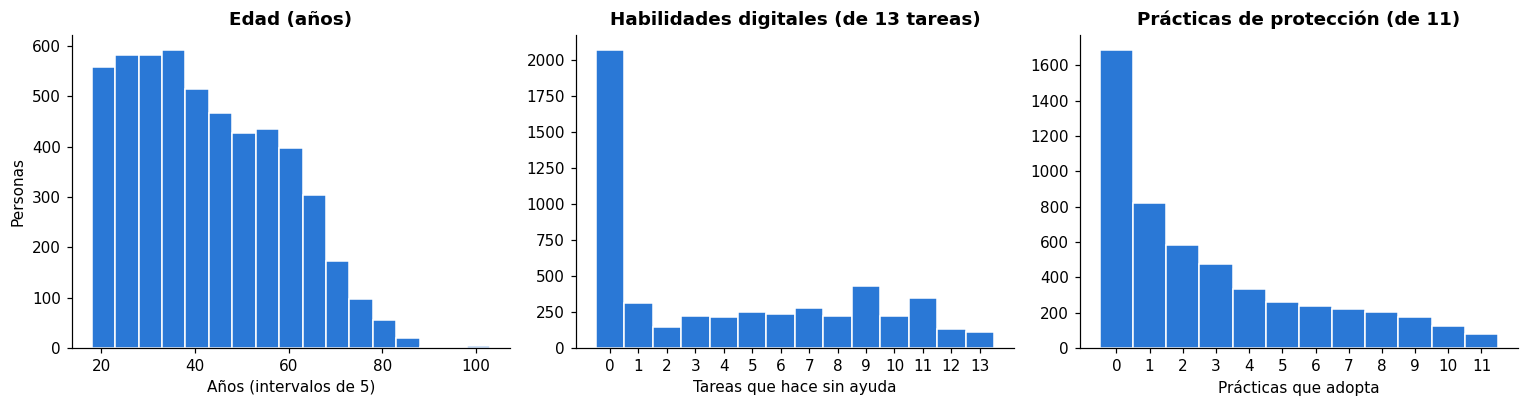

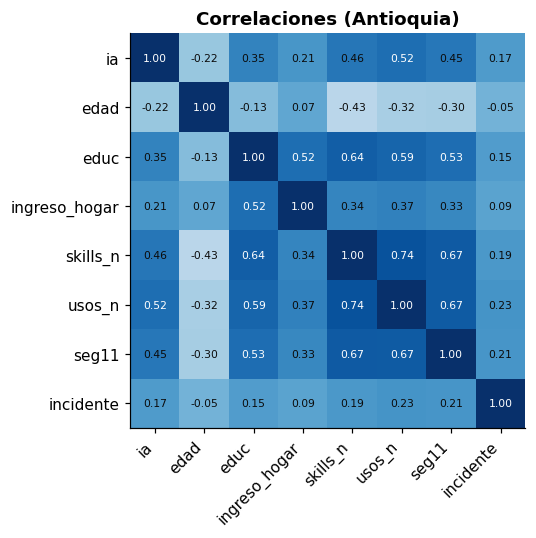

In [4]:
# Este bloque hace dos revisiones visuales antes de modelar, solo con personas de Antioquia (a).
# 1. Histogramas: muestran cuántas personas hay en cada valor de edad, de habilidades digitales y de prácticas de protección, es decir, cómo se reparten los datos.
# 2. Mapa de correlaciones: muestra qué tanto se mueven juntas las variables clave.
# Sirve para detectar datos raros y tener las primeras pistas, sin concluir nada todavía: una correlación no prueba causa.

# 1. Histogramas.
# Se crea una figura con 3 gráficos en una fila (1 fila, 3 columnas) de 14 x 3,8 pulgadas.
fig,ax=plt.subplots(1,3,figsize=(14,3.8))

# Primer histograma: edad. Cada barra agrupa 5 años (18-22, 23-27, ...).
# bins=np.arange(18,104,5) define los cortes: de 18 a 103 saltando de 5 en 5.
# edgecolor='white' dibuja un borde blanco para distinguir una barra de otra.
ax[0].hist(a.edad,bins=np.arange(18,104,5),color=AZUL,edgecolor='white',linewidth=1); ax[0].set_title('Edad (años)'); ax[0].set_xlabel('Años (intervalos de 5)'); ax[0].set_ylabel('Personas')

# Segundo histograma: habilidades digitales, de 0 a 13 tareas que la persona sabe hacer.
# Los cortes van de -0,5 a 14,5 en pasos de 1 para que cada barra quede
# centrada sobre su número entero (0, 1, 2, ... 13). set_xticks pone esos números.
ax[1].hist(a.skills_n,bins=np.arange(-.5,14.5,1),color=AZUL,edgecolor='white',linewidth=1); ax[1].set_xticks(range(0,14)); ax[1].set_title('Habilidades digitales (de 13 tareas)'); ax[1].set_xlabel('Tareas que hace sin ayuda')

# Tercer histograma: prácticas de protección, de 0 a 11.
# seg11 guarda una fracción (0 a 1); se multiplica por 11 para volver al conteo de prácticas. dropna() quita a quienes no tienen dato.
ax[2].hist(a.seg11.dropna()*11,bins=np.arange(-.5,12.5,1),color=AZUL,edgecolor='white',linewidth=1); ax[2].set_xticks(range(0,12)); ax[2].set_title('Prácticas de protección (de 11)'); ax[2].set_xlabel('Prácticas que adopta')

# Acomoda los 3 gráficos para que no se superpongan los títulos ni los ejes.
plt.tight_layout()

# Se guarda la figura como imagen PNG en la carpeta graficos/ (dpi=150 da buena calidad; bbox_inches='tight' recorta márgenes; facecolor='white' evita fondo transparente).
plt.savefig(SALIDA + 'graficos/eda_histogramas.png',
            dpi=150, bbox_inches='tight', facecolor='white')   # guarda el gráfico en PNG
# Se muestra el gráfico en el cuaderno.
plt.show()

# 2. Mapa de correlaciones.
# num = variables que se comparan entre sí.
#  ia (usa IA, 1/0) | edad | educ (nivel educativo) | ingreso_hogar (categoría 1-7)
#  skills_n (habilidades) | usos_n (usos de internet) | seg11 (protección)
#  incidente (tuvo algún incidente, 1/0)
num=['ia','edad','educ','ingreso_hogar','skills_n','usos_n','seg11','incidente']

# a[num].corr() calcula la correlación de cada variable con las demás.
# Va de -1 a +1: cerca de +1 suben juntas; cerca de -1, una sube y la otra baja; cerca de 0, no se mueven juntas de forma lineal.
# imshow dibuja la tabla como cuadrícula coloreada (más azul = valor mayor).
cm=a[num].corr(); fig,ax=plt.subplots(figsize=(6.5,5)); im=ax.imshow(cm.values,cmap='Blues',vmin=-1,vmax=1)

# Se pone los nombres de las variables en los ejes (rotados 45° para que se lean).
ax.set_xticks(range(len(num))); ax.set_xticklabels(num,rotation=45,ha='right'); ax.set_yticks(range(len(num))); ax.set_yticklabels(num)

# Se escribe el número de la correlación dentro de cada cuadro (2 decimales).
# Si el valor absoluto supera 0,5 el cuadro es oscuro y el texto va en blanco; si no, va en el color de texto normal para que se lea bien.
for i in range(len(num)):
    for j in range(len(num)): ax.text(j,i,f'{cm.values[i,j]:.2f}',ha='center',va='center',fontsize=7,color='white' if abs(cm.values[i,j])>.5 else TEXTO)

ax.set_title('Correlaciones (Antioquia)'); plt.tight_layout()

# Se guarda el mapa como PNG y lo muestra.
plt.savefig(SALIDA + 'graficos/eda_correlaciones.png',
            dpi=150, bbox_inches='tight', facecolor='white')   # guarda el gráfico en PNG
plt.show()

**Lectura de histogramas y correlaciones** (adultos con internet de Antioquia, sin ponderar).
- **Edad:** la mitad tiene 40 años o menos (mediana 40; la mitad central entre 29 y 55). Hay pocas personas de más de 75.
- **Tareas digitales sin ayuda:** el 40 % no hace ninguna, casi la mitad hace 2 o menos y cerca de 3 de cada 10 hacen 8 o más: hay un grupo grande con pocas habilidades y otro con muchas. *Ojo:* el cuestionario mide estas tareas «en el computador de escritorio, portátil o tableta», así que quien solo usa celular puede quedar en cero sin ser poco hábil.
- **Prácticas de protección:** el 32 % no adopta ninguna de las 11, casi la mitad adopta 1 o ninguna y solo 1 de cada 4 adopta 5 o más.
- **Correlaciones:** tareas, usos y protección se mueven juntas (0,67 a 0,74): miden aspectos de una misma madurez digital, por eso se resumen en un solo indicador. Con el uso de IA se relacionan más los usos de internet (0,52), las tareas (0,46) y la protección (0,45); la educación llega a 0,35. La edad tiene correlación negativa con las tareas (−0,43), los usos (−0,32) y el uso de IA (−0,22): a mayor edad, menos habilidades y menos IA. Los incidentes se relacionan poco con todo (máximo 0,23).
- *Correlación no es causa:* solo orienta qué variables entran al modelo. Las variables se usan sin transformar salvo la zona (codificada en variables 0/1) y educación (escala ordinal 1–17).

**Gráfico G1.** Se compara el uso de IA de Antioquia con los demás departamentos usando el factor de expansión de la encuesta, para saber si el territorio está adelante o atrás.

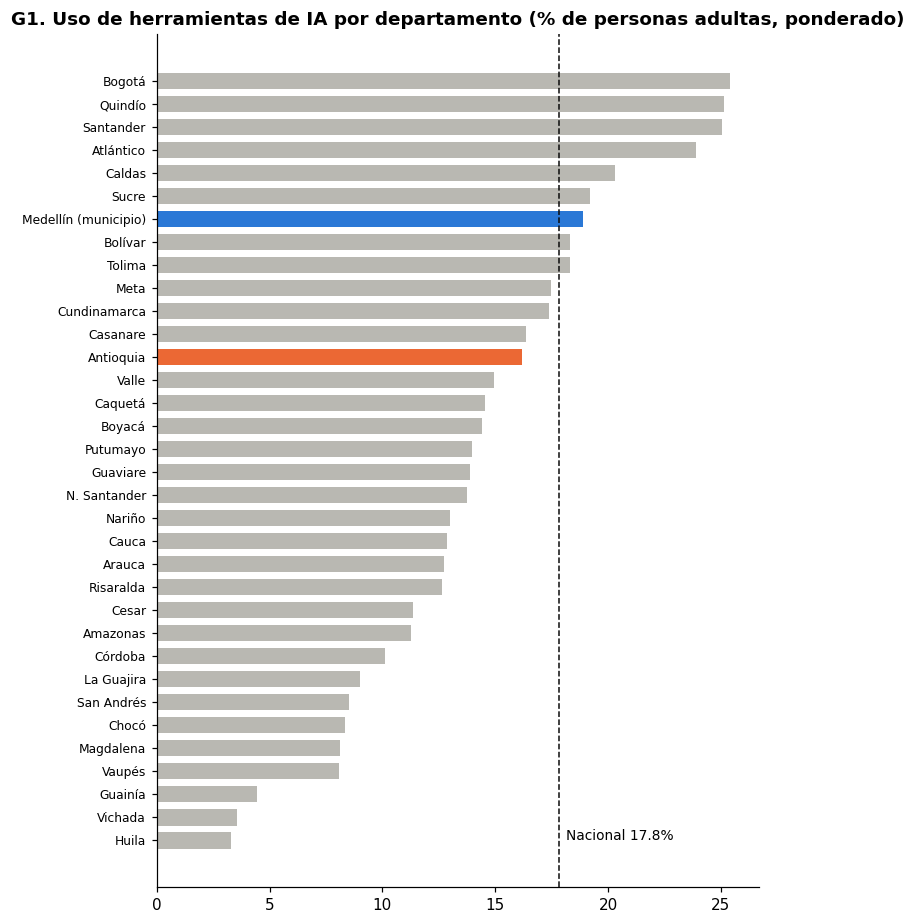

Antioquia: 16.2%  → puesto 12 de 33 (nacional 17.8%)
Medellín (municipio de Antioquia): 18.9% (n=1174) | resto de Antioquia: 14.4%


In [5]:
# Este bloque dibuja el Gráfico G1: el porcentaje de personas adultas con internet que usan herramientas de IA en cada departamento,
# ordenado de menor a mayor, para ver en qué lugar queda Antioquia. Además se agrega a Medellín como barra aparte.
# Todos los porcentajes son ponderados con el factor de expansión (fex), es decir, cada persona cuenta según a cuántas personas representa en el país.

# 1. Porcentaje de uso de IA por departamento
# Se agrupa a los adultos de todo el país (b) por departamento (dpto).
# Para cada uno calcula n (personas en la muestra) e ia (porcentaje ponderado que usa IA, por eso se multiplica por 100). Luego se ordena de menor a mayor.
dep = b.groupby('dpto').apply(lambda x: pd.Series({'n':len(x),'ia':100*wm(x.ia,x.fex)})).reset_index().sort_values('ia')

# 2. Diccionario con los nombres de los departamentos
# La base solo trae el código numérico del DANE (5 = Antioquia, 11 = Bogotá, etc.). Este diccionario traduce cada código a su nombre para el gráfico.
nom={11:'Bogotá',5:'Antioquia',76:'Valle',25:'Cundinamarca',68:'Santander',8:'Atlántico',13:'Bolívar',54:'N. Santander',19:'Cauca',73:'Tolima',50:'Meta',52:'Nariño',23:'Córdoba',66:'Risaralda',17:'Caldas',15:'Boyacá',47:'Magdalena',20:'Cesar',41:'Huila',44:'La Guajira',70:'Sucre',63:'Quindío',85:'Casanare',86:'Putumayo',18:'Caquetá',27:'Chocó',81:'Arauca',95:'Guaviare',91:'Amazonas',88:'San Andrés',94:'Guainía',99:'Vichada',97:'Vaupés'}

# 3. Nombres, promedio nacional y puesto de Antioquia
# dep['nombre'] pone el nombre a cada código.
# nal es el porcentaje nacional de uso de IA (línea de referencia del gráfico).
# rank cuenta cuántos departamentos tienen un porcentaje MAYOR que el de Antioquia y le suma 1: ese es su puesto (puesto 1 = el departamento con más uso de IA).
dep['nombre']=dep.dpto.map(nom); nal=100*wm(b.ia,b.fex)
rank=int((dep.ia>dep[dep.dpto==5].ia.iloc[0]).sum()+1)

# 4. Medellín como barra aparte
# Medellín (municipio 5001) se agrega como barra aparte: es un municipio de Antioquia, no un departamento, y no entra al ranking
# med = adultos de Antioquia que viven en Medellín; ia_med = su porcentaje de uso de IA.
med=a[a.mpio==5001]; ia_med=100*wm(med.ia,med.fex)

# 5. Unir Medellín a la tabla del gráfico
# Se crea una fila para Medellín con dpto = 0 (código inventado, solo para distinguirla de los departamentos reales) y se pega a la tabla.
# Se ordena de nuevo para que quede en su lugar según su porcentaje.
dep_g=pd.concat([dep,pd.DataFrame({'dpto':[0],'n':[len(med)],'ia':[ia_med],'nombre':['Medellín (municipio)']})],ignore_index=True).sort_values('ia')

# 6. Colores de las barras
# Antioquia en naranja, Medellín en azul y el resto en gris.
colores=[NARANJA if x==5 else AZUL if x==0 else GRIS for x in dep_g.dpto]

# 7. Dibujo del gráfico de barras horizontales
# figsize=(7,8.5) lo hace alto para que quepan los 34 nombres. height=.7 da espacio entre barras.
fig,ax=plt.subplots(figsize=(7,8.5)); ax.barh(dep_g.nombre,dep_g.ia,color=colores,height=.7)

# Línea punteada vertical en el promedio nacional, con su etiqueta (se escribe junto a la base del gráfico). labelsize=8 reduce el tamaño de los nombres.
ax.axvline(nal,color=TEXTO,ls='--',lw=1); ax.text(nal+.3,0,f'Nacional {nal:.1f}%',fontsize=9); ax.tick_params(axis='y',labelsize=8)
ax.set_title('G1. Uso de herramientas de IA por departamento (% de personas adultas, ponderado)'); plt.tight_layout()

# 8. Guardar el gráfico como imagen PNG y se muestra
plt.savefig(SALIDA + 'graficos/g01_uso_ia_departamento.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# 9. Resumen escrito de los resultados
# Línea 1: porcentaje de Antioquia, su puesto entre los departamentos y el promedio nacional.
# Línea 2: Medellín (con su tamaño de muestra n) frente al resto de Antioquia, para compararlo con el promedio departamental.
print(f'Antioquia: {100*wm(a.ia,a.fex):.1f}%  → puesto {rank} de {len(dep)} (nacional {nal:.1f}%)')
print(f'Medellín (municipio de Antioquia): {ia_med:.1f}% (n={len(med)}) | resto de Antioquia: {100*wm(a[a.mpio!=5001].ia,a[a.mpio!=5001].fex):.1f}%')


**Lectura Gráfico G1.** Cada barra es el porcentaje de adultos con internet que usó herramientas de IA en los últimos 12 meses (ponderado con el factor de expansión). Antioquia (naranja) tiene **16,2 %** y ocupa el **puesto 12 de 33**, algo por debajo del promedio nacional (17,8 %, línea punteada) y lejos de Bogotá (25,4 %), Quindío y Santander (25,1 %) y Atlántico (23,9 %); en el otro extremo están Huila (3,3 %), Vichada (3,6 %) y Guainía (4,5 %). La encuesta incluye a Bogotá D.C., que el DANE trata como un departamento más (código 11). La barra azul es **Medellín** (municipio con 1.174 personas en la muestra): 18,9 %, por encima del promedio nacional, mientras que el resto de Antioquia queda en 14,4 %. Medellín no entra al ranking porque es un municipio y no un departamento.

Antioquia esconde una desigualdad interna: Medellín sube el promedio del departamento y el resto se queda atrás (ver G2 y G9).

**Gráfico G2 y G3.** El Gráfico G2 compara el uso de IA según la zona del territorio (cabecera municipal, centro poblado y rural disperso) y El Gráfico G3 según el grupo de edad y el sexo, para ver quién queda por fuera. Los porcentajes están ponderados y cada grupo muestra cuántas personas hay en la muestra (n).

Gráfico G2 · % que usa IA por zona (ponderado) y n:
                ia_%     n
clase_g                   
Cabecera        17.6  3230
Centro poblado   7.8   717
Rural disperso   8.3  1272

Gráfico G3 · % que usa IA por edad y sexo (ponderado; columna 0 = hombres, 1 = mujeres):
sexo_mujer     0     1
edad_g                
18-24       22.4  28.3
25-34       25.8  18.8
35-44       19.8  20.2
45-54       11.5   7.4
55-64        4.8   5.0
65+          3.5   0.4

Por grupo de edad (ambos sexos):
        ia_%       n
edad_g              
18-24   25.3   806.0
25-34   22.2  1153.0
35-44   20.0  1056.0
45-54    9.3   880.0
55-64    4.9   809.0
65+      1.6   515.0

45 a 64 años: n=1689, usa IA 7.3% | 18 a 44 años: 22.3%


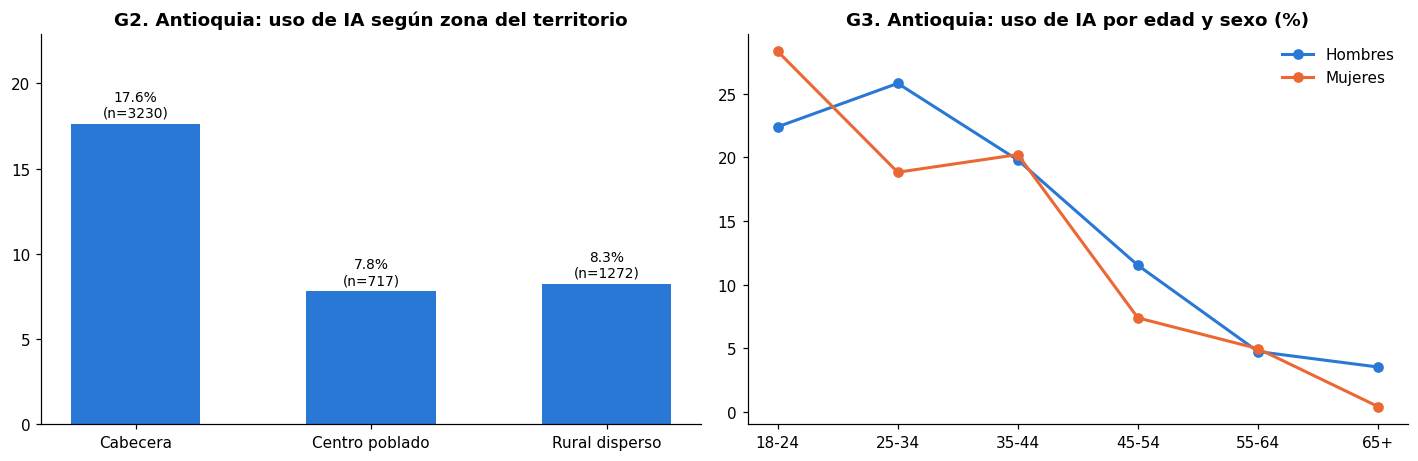

In [6]:
# Este bloque calcula y dibuja dos gráficos del uso de IA en Antioquia:
#   Gráfico G2: por zona del territorio (cabecera, centro poblado, rural disperso).
#   Gráfico G3: por grupo de edad, separando hombres y mujeres.
# Todos los porcentajes son ponderados con el factor de expansión (fex):
# Cada persona cuenta según a cuántas personas representa.
# n es la cantidad real de personas encuestadas (sin ponderar), para saber qué tan sólida es cada cifra.

# 1. Uso de IA por zona (Gráfico G2)
# Se agrupa por zona (clase_g) y calcula el porcentaje ponderado que usa IA en cada una. reindex fija el orden: cabecera, centro poblado, rural disperso.
# n_ cuenta cuántas personas hay en cada zona.
t=a.groupby('clase_g').apply(lambda x:100*wm(x.ia,x.fex)).reindex(['Cabecera','Centro poblado','Rural disperso']); n_=a.groupby('clase_g').size().reindex(t.index)

# 2. Uso de IA por edad y sexo (Gráfico G3)
# Se agrupa por grupo de edad y por sexo (0 = hombre, 1 = mujer). unstack() deja los grupos de edad en las filas y una columna por cada sexo.
l=a.groupby(['edad_g','sexo_mujer']).apply(lambda x:100*wm(x.ia,x.fex)).unstack()

# 3. Tablas impresas
# Primero la tabla de zonas (porcentaje y n). Luego la de edad por sexo.
print('Gráfico G2 · % que usa IA por zona (ponderado) y n:'); print(pd.DataFrame({'ia_%':t.round(1),'n':n_}))
print('\nGráfico G3 · % que usa IA por edad y sexo (ponderado; columna 0 = hombres, 1 = mujeres):'); print(l.round(1))

# 4. Edad con ambos sexos juntos
# Porcentaje y n por grupo de edad. Sirve para ver el patrón de edad sin mezclarlo con la diferencia por sexo.
ge=a.groupby('edad_g').apply(lambda x:pd.Series({'ia_%':100*wm(x.ia,x.fex),'n':len(x)})).round(1); print('\nPor grupo de edad (ambos sexos):'); print(ge)

# 5. Comparación clave para el público de 45 a 64 años
# s45 = personas de 45 a 64 años. Se imprime su n y su porcentaje de uso de IA, y se compara con las de 18 a 44.
s45=a[(a.edad>=45)&(a.edad<=64)]; print('\n45 a 64 años: n=%d, usa IA %.1f%% | 18 a 44 años: %.1f%%' % (len(s45),100*wm(s45.ia,s45.fex),100*wm(a[a.edad<45].ia,a[a.edad<45].fex)))

# 6. Figura con dos gráficos lado a lado
fig,ax=plt.subplots(1,2,figsize=(13,4.3))

# Para la Grafíca G2: barras azules, una por zona. width=.55 las hace delgadas.
ax[0].bar(t.index,t.values,color=AZUL,width=.55)

# Encima de cada barra se escribe el porcentaje y, entre paréntesis, su n.
# v+.4 sube el texto un poco sobre la barra para que no la tape.
for i,v in enumerate(t.values): ax[0].text(i,v+.4,f'{v:.1f}%\n(n={n_.iloc[i]})',ha='center',fontsize=9)

# ylim deja 30 % de espacio sobre la barra más alta para que quepan las etiquetas.
ax[0].set_ylim(0,t.max()*1.3); ax[0].set_title('G2. Antioquia: uso de IA según zona del territorio')

# Para la Grafíca G3: dos líneas, azul para hombres (columna 0) y naranja para mujeres (columna 1).
# marker='o' pone un punto en cada grupo de edad; lw=2 engrosa la línea.
ax[1].plot(l.index.astype(str),l[0],color=AZUL,marker='o',lw=2,label='Hombres'); ax[1].plot(l.index.astype(str),l[1],color=NARANJA,marker='o',lw=2,label='Mujeres')
ax[1].legend(frameon=False); ax[1].set_title('G3. Antioquia: uso de IA por edad y sexo (%)'); plt.tight_layout()

# 7. Guardar la figura como PNG y se muestra
plt.savefig(SALIDA + 'graficos/g02_g03_clase_edad_sexo.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

**Lectura de las Gráficas G2 y G3**

*De la Gráfica G2:* en la cabecera usan IA el 17,6 % (n = 3.230), más del doble que en el centro poblado (7,8 %, n = 717) y en el rural disperso (8,3 %, n = 1.272).

*De la Gráfica G3:* el uso cae con la edad: 25,3 % entre 18 y 24 años, 22,2 % entre 25 y 34 y 20,0 % entre 35 y 44; luego baja con fuerza a 9,3 % entre 45 y 54, 4,9 % entre 55 y 64 y 1,6 % después de los 65. Las líneas de hombres y mujeres se cruzan y cambian de signo según la edad, sin una brecha consistente (cada punto se calcula con pocas personas).

En Antioquia, el **22,3 %** de las personas de 18 a 44 años con internet usa IA, frente al **7,3 %** de las personas de 45 a 64. Este grupo, junto con los territorios no urbanos, es donde las asesorías de células Senior tiene ventaja de confianza y cercanía.

** Gráfico G4.** Un mapa de calor cruza la educación (filas) con la edad (columnas): cada casilla es el porcentaje de personas de ese grupo que usa IA, y el color más oscuro significa más uso. Muestra dónde se concentra el uso y dónde hay población con formación que aún no la usa. Se calcula sin ponderar y algunas casillas tienen pocas personas.

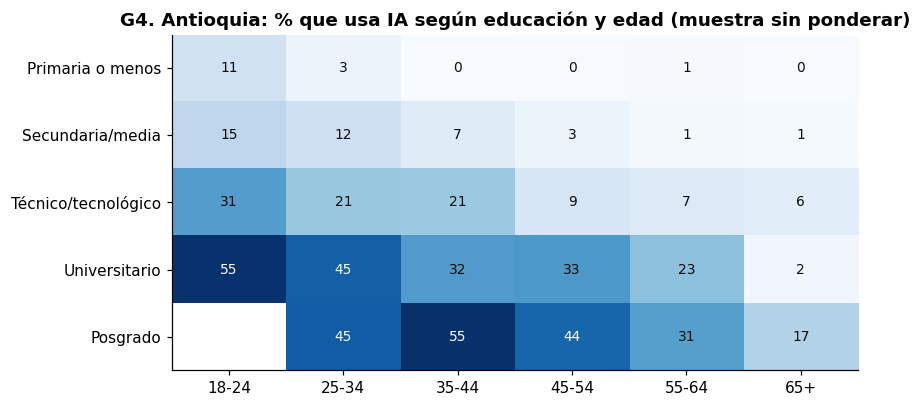

In [7]:
# Este bloque dibuja el Gráfico G4: un mapa de calor que cruza el nivel educativo (filas) con el grupo de edad (columnas).
# Cada cuadro muestra qué porcentaje de las personas de ese grupo usa IA. Cuanto más oscuro el azul, más uso de IA.
# Sirve para ver si la edad y la educación pesan por separado o juntas.
# Ojo: aquí el porcentaje es "sin ponderar", se calcula sobre las personas encuestadas tal cual, sin multiplicar por el factor de expansión (fex).
# Por eso estos números pueden diferir un poco de los gráficos G2 y G3, que sí son ponderados.
# Se hace así porque en cruces tan pequeños el peso de unos pocos casos puede distorsionar la cifra y la idea es ver el patrón.

# 1. Construir la tabla del cruce
# pivot_table arma una tabla con una fila por nivel educativo (index) y una columna por grupo de edad (columns).
# values='ia' toma la variable de uso de IA (1 = usa, 0 = no usa)
# aggfunc='mean' saca el promedio de cada celda, que al ser 0 y 1 equivale a la proporción que usa IA.
# reindex fija el orden de las filas de menor a mayor educación. Al multiplicar por 100 queda en porcentaje.
# Si un cruce no tiene personas (por ejemplo, posgrado de 18 a 24 años), la celda queda vacía (NaN).
h=a.pivot_table(index='educ_g',columns='edad_g',values='ia',aggfunc='mean').reindex(['Primaria o menos','Secundaria/media','Técnico/tecnológico','Universitario','Posgrado'])*100

# 2. Crear la figura y poner colores a la tabla
# figsize=(8,3.8) define el tamaño (ancho 8 y alto 3,8 pulgadas). imshow pinta la tabla como cuadrícula de colores.
# cmap='Blues' usa la escala de azules (más oscuro = porcentaje mayor)
# aspect='auto' estira los cuadros para llenar el espacio.
fig,ax=plt.subplots(figsize=(8,3.8)); im=ax.imshow(h.values,cmap='Blues',aspect='auto')

# 3. Poner los nombres en los ejes
# Los grupos de edad van abajo (columnas) y los niveles educativos a la izquierda (filas).
ax.set_xticks(range(h.shape[1])); ax.set_xticklabels(h.columns); ax.set_yticks(range(h.shape[0])); ax.set_yticklabels(h.index)

# 4. Escribir el número dentro de cada cuadro
# Se recorre cada fila (i) y cada columna (j).
# Si la celda tiene dato (no es NaN), escribe el porcentaje redondeado a cero decimales (:.0f).
# Si el cuadro es muy oscuro (40 % o más) el número va en blanco para que se lea
# si es claro, va en el color de texto normal (TEXTO).
for i in range(h.shape[0]):
    for j in range(h.shape[1]):
        if not np.isnan(h.values[i,j]): ax.text(j,i,f'{h.values[i,j]:.0f}',ha='center',va='center',fontsize=9,color='white' if h.values[i,j]>=40 else TEXTO)

# 5. Título y ajuste de márgenes
# El título aclara que la muestra no está ponderada. tight_layout evita que se superpongan los textos.
ax.set_title('G4. Antioquia: % que usa IA según educación y edad (muestra sin ponderar)'); plt.tight_layout()

# 6. Guardar el gráfico como imagen PNG y se muestra
# dpi=150 da buena calidad, bbox_inches='tight' recorta los márgenes sobrantes y # facecolor='white' evita el fondo transparente.
# Se guarda en la carpeta graficos/ dentro de la carpeta salida/.
plt.savefig(SALIDA + 'graficos/g04_educacion_edad.png',
            dpi=150, bbox_inches='tight', facecolor='white')   # guarda el gráfico en PNG
plt.show()

**Lectura de la Gráfica G4**

La educación y la edad explican gran parte del uso de la IA. Con estudios universitarios, usa IA el 55 % de quienes tienen 18 a 24 años y el 45 % de 25 a 34; con primaria o menos, casi nadie la usa después de los 25 años (0 a 3 %). Entre los 55 y 64 años el uso es de 23 % con estudios universitarios y de 31 % con posgrado, frente a 7 % con formación técnica o tecnológica y 1 % con secundaria o primaria. Es decir, hay una población senior con capacidad (formación universitaria) que aún no ha adoptado la IA, y otra con poca formación para la que el reto es anterior a la IA.
*Ojo:* algunas casillas tienen pocas personas (por ejemplo, los mayores de 65 con estudios superiores); sirven como tendencia, no como cifra exacta.

**Gráfica G5.** Una caja (*boxplot*) compara el índice de protección digital entre quienes usan y no usan IA, y marca con una línea naranja el umbral que define el riesgo crítico.

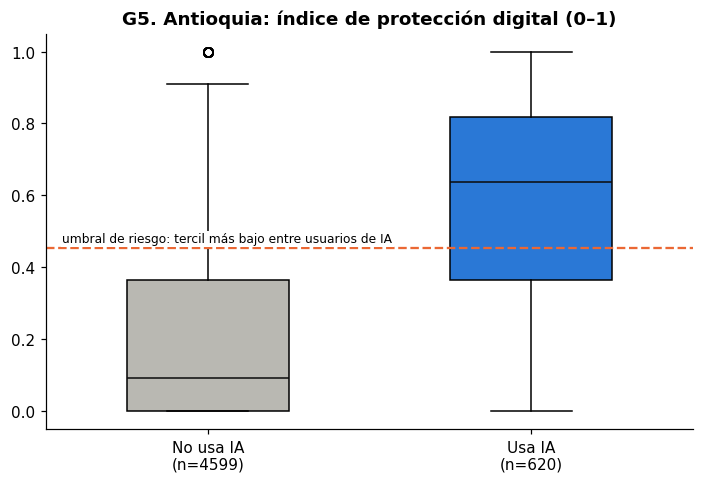

Umbral (tercil de usuarios de IA, nacional): 0.455 ≈ 5.0 de 11 prácticas
No usa IA | n=4599 | mediana 0.09 (1.0 de 11) | Q1 0.00 | Q3 0.36
Usa IA | n=620 | mediana 0.64 (7.0 de 11) | Q1 0.36 | Q3 0.82


In [8]:
# Este bloque dibuja el Gráfico G5:
# dos diagramas de caja (boxplots) que comparan el índice de protección digital (seg11, de 0 a 1) entre quienes NO usan IA y quienes SÍ la usan, solo en Antioquia.
# Además calcula el umbral de "riesgo crítico": el nivel de protección por debajo del cual se considera que una persona usuaria de IA está poco protegida.
# El índice es la fracción de las 11 prácticas de seguridad que la persona realiza: 0 = ninguna, 1 = las 11.

# 1. Crear la figura
# Una sola figura de 6,5 x 4,5 pulgadas.
fig,ax=plt.subplots(figsize=(6.5,4.5))

# 2. Separar los dos grupos
# bx es una lista con dos series: la primera trae el índice de protección de quienes no usan IA (ia == 0) y la segunda el de quienes sí la usan (ia == 1).
# dropna() quita a las personas sin dato para que no afecten el cálculo.
bx=[a[a.ia==0].seg11.dropna(), a[a.ia==1].seg11.dropna()]

# 3. Dibujar los diagramas de caja
# Un diagrama de caja resume muchas personas en una figura:
#  - la línea del centro es la mediana (la mitad de las personas queda por debajo);
#  - la caja va del cuartil 1 (Q1, 25 %) al cuartil 3 (Q3, 75 %), o sea que contiene al 50 % central del grupo;
#  - las líneas que salen de la caja (bigotes) muestran el resto del rango normal;
#  - los puntos sueltos son casos atípicos (muy distintos al resto).
# tick_labels pone el nombre de cada grupo con su n (número de personas).
# patch_artist=True permite rellenar las cajas de color; widths=.5 las hace más angostas.
bp=ax.boxplot(bx,tick_labels=[f'No usa IA\n(n={len(bx[0])})',f'Usa IA\n(n={len(bx[1])})'],patch_artist=True,widths=.5)

# 4. Colores
# La caja de quienes no usan IA va en gris y la de quienes usan IA en azul.
for p_,c in zip(bp['boxes'],[GRIS,AZUL]): p_.set_facecolor(c)
# La línea de la mediana se pinta del color del texto para que resalte sobre la caja.
for m_ in bp['medians']: m_.set_color(TEXTO)

# 5. Umbral de riesgo
# thr = cuantil 0,33 (tercil inferior) del índice de protección entre las personas que usan IA en TODO el país (b, no solo Antioquia).
#Significa que un tercio de los usuarios de IA del país tiene un índice igual o menor a ese valor.
# Se calcula con el país completo para tener una vara de medir única y no depender de la muestra de Antioquia. nanquantile ignora los vacíos.
thr=np.nanquantile(b[b.ia==1].seg11,0.33)

# Se dibuja una línea horizontal naranja punteada en el umbral y escribe una etiqueta sobre ella.
# El recuadro blanco detrás del texto (bbox) evita que la línea o los bigotes de las cajas lo atraviesen y dificulten la lectura.
ax.axhline(thr,color=NARANJA,ls='--'); ax.text(.55,thr+.015,'umbral de riesgo: tercil más bajo entre usuarios de IA',fontsize=8,bbox=dict(facecolor='white',edgecolor='none',pad=1))

# 6. Se pone el título y se guarda
ax.set_title('G5. Antioquia: índice de protección digital (0–1)'); plt.tight_layout()
plt.savefig(SALIDA + 'graficos/g05_proteccion.png',
            dpi=150, bbox_inches='tight', facecolor='white')   # guarda el gráfico en PNG
plt.show()

# 7. Resumen en texto
# Se imprime el umbral y su equivalente en prácticas: umbral x 11 = número de las 11 prácticas (redondeado a un decimal).
print('Umbral (tercil de usuarios de IA, nacional):', round(thr,3), '≈', round(thr*11,1), 'de 11 prácticas')

# Para cada grupo imprime: n (personas), mediana, su equivalente en prácticas de 11, y los cuartiles Q1 y Q3 (los bordes de la caja).
for nm,s in zip(['No usa IA','Usa IA'],bx): print(nm,'| n=%d | mediana %.2f (%.1f de 11) | Q1 %.2f | Q3 %.2f' % (len(s),s.median(),11*s.median(),s.quantile(.25),s.quantile(.75)))

**Lectura de la Gráfica G5**

Cada caja resume cómo se reparte el índice de protección, de 0 (ninguna de las 11 prácticas) a 1 (las 11). La línea oscura dentro de la caja es la mediana (la mitad de las personas queda por debajo), la caja contiene al 50 % central y los bigotes y puntos muestran los extremos.
- **No usan IA** (n = 4.599): mediana 0,09, es decir, 1 práctica de 11 o ninguna; la caja llega solo hasta 0,36 (4 prácticas).
- **Usan IA** (n = 620): mediana 0,64, unas 7 prácticas de 11, y la mitad central va de 4 a 9 prácticas. Protegen más, pero también son las personas más digitales en general.
- **Línea naranja (0,455, equivalente a 5 de 11 prácticas):** es el tercio de usuarios de IA del país con menos prácticas. Quien usa IA y queda en o por debajo de la línea está en **riesgo crítico**: usa una herramienta con 5 prácticas básicas o menos. En Antioquia es el 29 % de quienes usan IA, cerca de 3 de cada 10.
- La caja de quienes usan IA es ancha: conviven personas muy protegidas con otras que casi no adoptan prácticas, y esa dispersión es la que la regla de exposición busca señalar.

## Fase 3 · Modelos
**Estrategia común:** separación 80/20 **por hogar** (no por persona, porque las personas de un mismo hogar se parecen y habría fuga de información), validación cruzada agrupada por hogar, un modelo de referencia (*Dummy*, que solo repite la proporción general) y tres modelos reales: regresión logística, árbol de decisión y Random Forest. Se reportan el Índice C (-AUC-) (también llamado estadístico c: qué tan bien el modelo ordena a las personas, de 0,5 que equivale al azar a 1 que sería perfecto), el recall, la precisión y el F1; el umbral 0,5 se usa solo para comparar.

### Pregunta 1 · ¿Una persona con poca madurez digital usa IA? ¿Influye su contexto regional (municipio y zona) para que use IA?
`mad` = promedio estandarizado de habilidades (`skills_n`) y variedad de usos (`usos_n`). `brecha_mpio` = madurez de la persona menos la media del resto de su municipio (excluyendo a la persona).

**Por qué se comparan tres conjuntos de variables.** Se agregan de a poco para ver qué aporta cada grupo. Cada paso responde una parte de la pregunta:
1. **Solo perfil y hogar** (edad, sexo, educación, zona, ingreso y personas del hogar). Es el punto de partida: lo que se sabe de la persona sin preguntarle nada sobre internet. Incluye la **zona** donde vive.
2. **+ madurez propia** (`mad`). Responde la primera parte de la pregunta: si lo que la persona sabe hacer y usa en internet agrega información a su perfil.
3. **+ brecha frente al municipio** (`brecha_mpio`). Responde la segunda parte: si vivir en un municipio más o menos digital agrega algo más allá de la propia persona.
Si el Índice C sube en el paso 2 y no en el paso 3, la conclusión es que importa la persona y no solo el lugar. Ninguna de estas variables contiene el ítem 30 (uso de IA), para evitar la fuga de datos.

In [9]:
# Este bloque responde a la pregunta 1 del proyecto:
# ¿La madurez digital propia de una persona ayuda a predecir si usa IA?
# Para eso:
#   1) Se construye un índice de madurez digital (mad) y una "brecha" frente a su municipio;
#   2) Se entrenan modelos con tres conjuntos de variables, de menos a más información;
#   3) Se compara qué tan bien separa cada conjunto a quienes usan IA de quienes no (Índice C).
# El Índice C va de 0,5 (igual que lanzar una moneda) a 1,0 (separa perfecto).
# Nota: la variable que se predice es IA (ítem 30). NO se usa para construir ninguna de las variables de entrada, para evitar la fuga de datos.

# 1. Madurez digital (mad)
# usos_f: copia de usos_n en la que los vacíos se rellenan con la mediana, para no perder personas.
# z: función que estandariza una variable, es decir, le resta su promedio y la
# divide por su desviación. Así habilidades (0 a 13) y usos (0 a 29), que tienen
# escalas distintas, pesan igual al combinarse.
# mad: promedio de las dos variables estandarizadas. 0 es el promedio de Antioquia;
# positivo, más madurez que el promedio; negativo, menos.
a['usos_f']=a.usos_n.fillna(a.usos_n.median()); z=lambda s:(s-s.mean())/s.std()
a['mad']=(z(a.skills_n)+z(a.usos_f))/2

# 2. Madurez promedio del municipio, sin contar a la propia persona
# g agrupa la madurez por municipio (mpio). Para cada persona se calcula el
# promedio de las demás personas de su municipio: (suma del municipio - su propio
# valor) / (personas del municipio - 1). Se excluye a la propia persona
# ("leave-one-out", dejar uno fuera) para que su valor no influya en el promedio
# con el que se la compara; si no, la comparación estaría contaminada.
g=a.groupby('mpio').mad; a['mad_mpio_loo']=(g.transform('sum')-a.mad)/(g.transform('count')-1)

# 3. Brecha frente al municipio
# Madurez de la persona menos madurez promedio de su municipio. Positiva: más
# madura que su entorno; negativa: menos madura que su entorno.
a['brecha_mpio']=a.mad-a.mad_mpio_loo

# 4. Zona en dos columnas de 0 y 1 ("one-hot")
# El modelo necesita números, no texto. Se crean dos columnas: clase_2 vale 1 si
# vive en centro poblado y clase_3 vale 1 si vive en rural disperso. Si ambas son 0,
# vive en cabecera, que queda como referencia (por eso no necesita su propia columna).
a['clase_2']=(a.clase==2)*1; a['clase_3']=(a.clase==3)*1   # one-hot de clase (cabecera = referencia)

# 5. Variables base: perfil y hogar
# Edad, sexo, educación, zona, ingreso del hogar y personas en el hogar. Es el
# punto de partida, sin información sobre qué sabe hacer o usa la persona.
base=['edad','sexo_mujer','educ','clase_2','clase_3','ingreso_hogar','personas_hogar']

# 6. Las dos plantillas de modelo que se reutilizan en toda la Fase 3
# LR crea una regresión logística: primero estandariza las variables y luego
# ajusta el modelo. class_weight='balanced' compensa que hay muchos más "no usa
# IA" que "usa IA", para que el modelo no ignore al grupo pequeño.
# RF crea un Random Forest: 300 árboles de decisión que "votan"; min_samples_leaf=15
# evita árboles que memoricen casos sueltos; random_state=0 hace que el resultado
# se repita igual cada vez; n_jobs=-1 usa todos los núcleos disponibles.
# Se definen como funciones (lambda) para crear un modelo NUEVO en cada uso.
LR=lambda:make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,class_weight='balanced'))
RF=lambda:RandomForestClassifier(300,min_samples_leaf=15,class_weight='balanced',random_state=0,n_jobs=-1)

# 7. Función que mide el Índice C con validación cruzada por hogar
# Recibe los datos, las variables de entrada (feats), la variable a predecir (y),
# el modelo y el número de partes (k = 5).
# - X rellena los vacíos con la mediana de cada variable.
# - GroupKFold(5) divide a las personas en 5 partes asegurando que todas las
#   personas de un mismo hogar (UID_ENCUESTA) queden juntas en la misma parte.
#   Así el modelo nunca se entrena con un familiar de quien va a predecir, lo que
#   inflaría el resultado.
# - cross_val_predict entrena con 4 partes y predice la quinta, y así 5 veces,
#   de modo que cada persona recibe una probabilidad calculada por un modelo que
#   NO la vio al entrenar.
# - roc_auc_score compara esas probabilidades con la realidad y devuelve el Índice C.
def cv_auc(df,feats,y,model,k=5):
    X=df[feats].fillna(df[feats].median())
    p=cross_val_predict(model,X,df[y],groups=df.UID_ENCUESTA,cv=GroupKFold(k),method='predict_proba')[:,1]
    return roc_auc_score(df[y],p)

# 8. Comparar tres conjuntos de variables
# Se calcula el Índice C de ambos modelos con: (a) solo perfil y hogar; (b) más la
# madurez propia; (c) más madurez y brecha con el municipio. Cada fila de rows
# guarda el nombre del conjunto y sus dos Índice C.
rows=[]
for nm,f in [('Solo perfil y hogar',base),('+ madurez propia',base+['mad']),('+ madurez y brecha vs municipio',base+['mad','brecha_mpio'])]:
    rows.append([nm,cv_auc(a,f,'ia',LR()),cv_auc(a,f,'ia',RF())])

# 9. Mostrar la tabla de resultados
# Se convierte en tabla, se redondea a 3 decimales y se imprime sin el índice.
cv=pd.DataFrame(rows,columns=['Conjunto de variables','Índice C reg. logística','Índice C Random Forest']).round(3); print(cv.to_string(index=False))

# 10. Dos referencias adicionales
# Índice C usando únicamente la brecha con el municipio, y usando únicamente la edad,
# para saber cuánto aporta cada una por separado.
print('Solo la brecha vs municipio:', round(cv_auc(a,['brecha_mpio'],'ia',LR()),3), '| solo la edad:', round(cv_auc(a,['edad'],'ia',LR()),3))

          Conjunto de variables  Índice C reg. logística  Índice C Random Forest
            Solo perfil y hogar                    0.839                   0.834
               + madurez propia                    0.910                   0.905
+ madurez y brecha vs municipio                    0.910                   0.907
Solo la brecha vs municipio: 0.894 | solo la edad: 0.702


**Modelos finales de la pregunta 1 (qué y por qué).** Se separa 80/20 por hogar y se comparan una regresión logística, un árbol de profundidad 4 y un Random Forest contra un modelo de referencia. Se reportan métricas, matriz de confusión e importancia de variables.

             Modelo  Índice C  Recall  Precisión    F1
 Dummy (referencia)     0.500   0.000      0.000 0.000
Regresión logística     0.905   0.900      0.327 0.479
    Árbol (prof. 4)     0.891   0.909      0.293 0.443
      Random Forest     0.900   0.818      0.380 0.519

Matriz de confusión (regresión logística, test): filas=real [no usa, usa], columnas=predicho
[[726 204]
 [ 11  99]]

Prevalencia de uso de IA en test: 0.106 | n train 4179 | n test 1040

Importancia por permutación (caída del Índice C, Random Forest):
Madurez digital (habilidades y usos)    0.129
Brecha frente al municipio              0.023
Edad                                    0.006
Ingreso del hogar (categoría 1 a 7)     0.002
Nivel educativo                         0.001
Zona: rural disperso                    0.000
Personas en el hogar                    0.000
Sexo al nacer (mujer)                   0.000
Zona: centro poblado                   -0.001


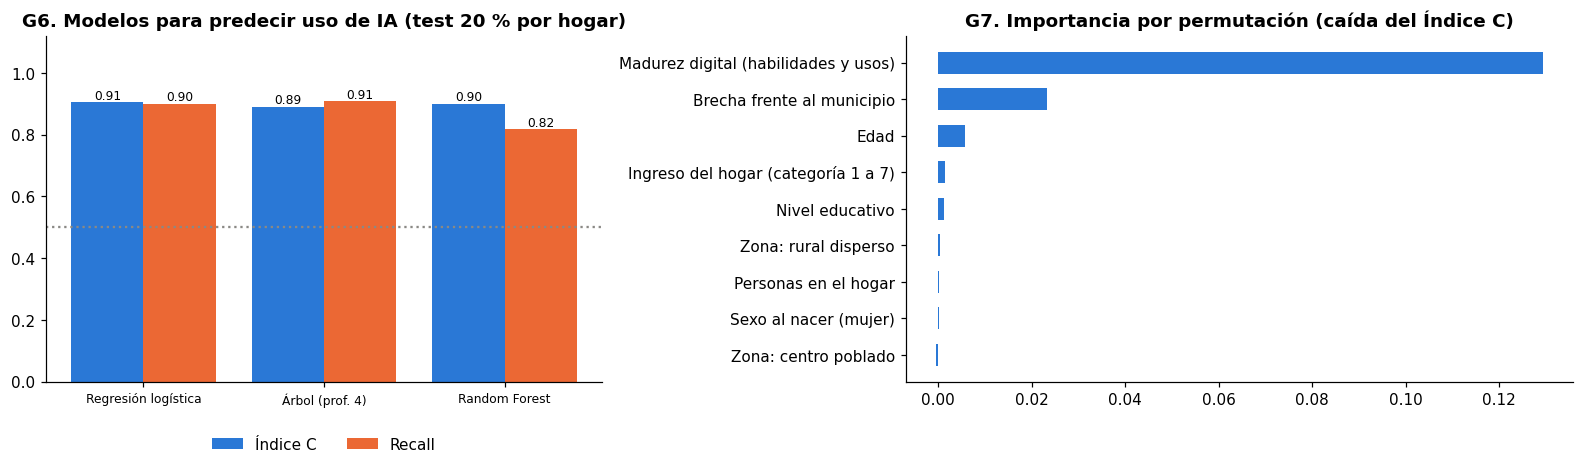

In [10]:
# Este bloque entrena y compara los modelos finales de la pregunta 1 y dibuja los Gráficos G6 y G7.
# 1. Se arma la lista de variables (feats): las variables base, la madurez digital (mad) y la brecha frente al municipio.
# 2. Se separa a las personas en 80 % para entrenar y 20 % para probar; los miembros de un mismo hogar quedan siempre en el mismo lado.
# 3. Los vacíos se rellenan con la mediana de las personas de entrenamiento, para que la parte de prueba no influya en el relleno.
# 4. Se entrenan cuatro modelos: uno de referencia (Dummy, que solo repite la proporción general) y tres reales (regresión logística, árbol de decisión y Random Forest).
# 5. Con el 20 % de prueba se calcula, para cada modelo, el Índice C, el recall, la precisión y el F1.
# 6. Se imprime la matriz de confusión de la regresión logística y la importancia por permutación del Random Forest, que mide cuánto empeora el modelo si se mezclan los valores de una variable.
# 7. Se dibujan el Gráfico G6 (comparación de modelos) y el Gráfico G7 (importancia de las variables) y se guardan como imagen PNG.
feats=base+['mad','brecha_mpio']
tr,te=next(GroupShuffleSplit(1,test_size=.2,random_state=42).split(a,groups=a.UID_ENCUESTA)); A,B=a.iloc[tr],a.iloc[te]
med=A[feats].median(); Xtr,Xte=A[feats].fillna(med),B[feats].fillna(med)
mods={'Dummy (referencia)':DummyClassifier(strategy='prior'),'Regresión logística':LR(),'Árbol (prof. 4)':DecisionTreeClassifier(max_depth=4,min_samples_leaf=30,class_weight='balanced',random_state=0),'Random Forest':RF()}
rows=[]; fitted={}
for n,m in mods.items():
    m.fit(Xtr,A.ia); p=m.predict_proba(Xte)[:,1]; yh=(p>=.5)*1 if 'Dummy' not in n else np.zeros(len(B))
    rows.append([n,roc_auc_score(B.ia,p),recall_score(B.ia,yh),precision_score(B.ia,yh,zero_division=0),f1_score(B.ia,yh,zero_division=0)]); fitted[n]=m
mt=pd.DataFrame(rows,columns=['Modelo','Índice C','Recall','Precisión','F1']).round(3); print(mt.to_string(index=False))
from sklearn.metrics import confusion_matrix
cmx=confusion_matrix(B.ia,(fitted['Regresión logística'].predict_proba(Xte)[:,1]>=.5)*1); print('\nMatriz de confusión (regresión logística, test): filas=real [no usa, usa], columnas=predicho'); print(cmx); print('\nPrevalencia de uso de IA en test:', round(B.ia.mean(),3), '| n train', len(A), '| n test', len(B))
pi=permutation_importance(fitted['Random Forest'],Xte,B.ia,scoring='roc_auc',n_repeats=15,random_state=0); imp=pd.Series(pi.importances_mean,index=feats).sort_values()
# Se cambian los nombres técnicos de las variables por nombres completos para el Gráfico G7 y para la tabla impresa.
# nombres_g7 es un diccionario que traduce cada nombre del modelo a su descripción.
# Si alguna variable no está en el diccionario, se deja con su nombre original.
nombres_g7 = {'edad':'Edad', 'sexo_mujer':'Sexo al nacer (mujer)', 'educ':'Nivel educativo', 'clase_2':'Zona: centro poblado',
              'clase_3':'Zona: rural disperso', 'ingreso_hogar':'Ingreso del hogar (categoría 1 a 7)', 'personas_hogar':'Personas en el hogar',
              'mad':'Madurez digital (habilidades y usos)', 'brecha_mpio':'Brecha frente al municipio'}
imp.index=[nombres_g7.get(v,v) for v in imp.index]
fig,ax=plt.subplots(1,2,figsize=(14.5,4.4),gridspec_kw={'width_ratios':[1,1.2]}); m2=mt[~mt.Modelo.str.startswith('Dummy')]; x=np.arange(len(m2))
ax[0].bar(x-.2,m2['Índice C'],.4,color=AZUL,label='Índice C'); ax[0].bar(x+.2,m2.Recall,.4,color=NARANJA,label='Recall'); ax[0].set_xticks(x); ax[0].set_xticklabels(m2.Modelo,fontsize=8); ax[0].axhline(.5,color='#8a8985',ls=':'); ax[0].set_ylim(0,1.12); ax[0].legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.12),ncol=2)   # leyenda debajo de las barras
for i,v in enumerate(m2['Índice C']): ax[0].text(i-.2,v+.01,f'{v:.2f}',ha='center',fontsize=8)
for i,v in enumerate(m2.Recall): ax[0].text(i+.2,v+.01,f'{v:.2f}',ha='center',fontsize=8)
ax[0].set_title('G6. Modelos para predecir uso de IA (test 20 % por hogar)'); ax[1].barh(imp.index,imp.values,color=AZUL,height=.6); ax[1].set_title('G7. Importancia por permutación (caída del Índice C)'); print('\nImportancia por permutación (caída del Índice C, Random Forest):'); print(imp.sort_values(ascending=False).round(3).to_string())
plt.tight_layout()
plt.savefig(SALIDA + 'graficos/g06_g07_modelos_importancia.png',
            dpi=150, bbox_inches='tight', facecolor='white')   # guarda el gráfico en PNG
plt.show()

**Lectura de las métricas y la matriz de confusión (explicado fácil).** Piensa en el modelo como un vigilante que debe señalar quién usa IA entre 1.040 personas de prueba, de las cuales 110 sí la usan (cerca de 1 de cada 10 en esta muestra; ponderada por la población es 16,2 %).
- **Matriz de confusión:** es el conteo de aciertos y errores de la regresión logística. Encontró a 99 usuarios, dejó pasar a 11 y señaló por error a 204 personas que no la usan; acertó con 726 que no la usan.
- **Recall (0,90):** de cada 100 usuarios reales, el modelo encuentra 90 (99 de 110). Mide qué tan pocos usuarios se le escapan.
- **Precisión (0,33):** de cada 100 personas que señala, solo 33 la usan de verdad (99 de 303). Mide cuántas de sus alarmas son ciertas.
- **F1 (0,48):** un solo número que combina recall y precisión; baja si alguna de las dos es floja.
- **Índice C (0,91):** qué tan bien ordena a las personas. Si se toma al azar un usuario y un no usuario, el modelo le da más probabilidad al usuario el 91 % de las veces (0,5 sería lanzar una moneda).
- **Por qué no basta el accuracy:** como solo 1 de cada 10 usa IA en la muestra de prueba, un «modelo» que dijera «nadie usa IA» acertaría cerca del 90 % de las veces y no encontraría a nadie. Por eso se incluye el modelo de referencia (*Dummy*, recall 0) y se mira el recall.
- **Conclusión:** el modelo sirve para *priorizar* a quién mirar primero (encuentra a 9 de cada 10 usuarios), pero no para afirmar que una persona concreta usa IA: tiene muchas falsas alarmas. Para las clases desbalanceadas se usó `class_weight='balanced'`; no se aplicó SMOTE. Los tres modelos quedan casi empatados (Índice C 0,89 a 0,91), así que se prefiere el más simple, la regresión logística.

**Hallazgos de la pregunta 1.** Con solo perfil y hogar (edad, sexo, educación, clase, ingreso y personas del hogar) se predice razonablemente el uso de IA (Índice C 0,84); sumar la madurez digital propia sube a 0,91. La *brecha frente al municipio* no agrega nada (0,910 con regresión logística), y la importancia por permutación (G7) lo confirma: la madurez propia explica una caída del Índice C de 0,129, la brecha 0,023 y la edad 0,006; las demás variables casi no pesan. *Ojo:* la brecha por sí sola alcanza un Índice C de 0,89 porque se calcula como la madurez de la persona menos el promedio de su municipio, es decir, contiene la madurez de la persona; no es evidencia de que el territorio pese.
**Cómo leerlo con honestidad:** usar IA es en sí una señal de madurez digital, así que esta relación es una *asociación fuerte, no una causa*. En lenguaje de negocio: las personas con pocas habilidades y pocos usos digitales son las que no usan IA, sin importar si su municipio es «digital» o no; el acompañamiento debe ser individual, no solo territorial.

### Pregunta 2 · ¿Qué proporción de las personas que usan IA en Antioquia tiene pocas prácticas de ciberseguridad (riesgo crítico) y qué incidentes digitales reportan?
**Regla de exposición:** persona que usa IA y cuyo índice `seg11` está en el tercio más bajo de los usuarios de IA. Se contrasta con los incidentes de seguridad reportados por las propias personas.

**Pregunta 2 (qué y por qué).** Se calcula la regla de exposición, se compara con los incidentes reportados y se prueba si el índice de protección ayuda a predecir incidentes.

Usuarios de IA en Antioquia (muestra): 620 | con índice de protección: 620
Riesgo crítico (ponderado, entre usuarios de IA con índice): 29.2%

Incidentes digitales según uso de IA:
                n  incidente_%
grupo                         
No usa IA  4599.0         10.6
Usa IA      620.0         25.4

Incidentes según protección (todos los usuarios):
                       n  incidente_%
proteccion                           
Baja protección   4166.0          8.8
Mayor protección  1053.0         23.0

Índice C predecir incidente sin / con índice de protección: 0.699 / 0.721 | prevalencia 0.079


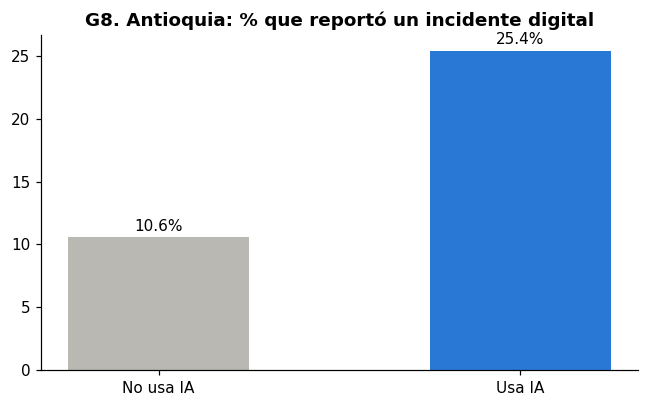

In [11]:
# Este bloque responde a la pregunta 2: quién usa IA con pocas prácticas de protección y qué muestran los incidentes reportados.
# 1. Se toma a los usuarios de IA de Antioquia (ai) y se marca como riesgo crítico a quien tiene un índice de protección igual o menor al umbral thr, que se calculó en el Gráfico G5 con los usuarios de IA de todo el país.
# 2. Se calcula el porcentaje ponderado de riesgo crítico entre los usuarios de IA que tienen índice de protección.
# 3. Se compara el porcentaje de personas que reportó algún incidente entre quienes usan y no usan IA.
# 4. Se compara el porcentaje de incidentes entre quienes tienen baja y mayor protección, para probar si el índice de protección anticipa los incidentes.
# 5. Se mide con el Índice C si agregar el índice de protección mejora la predicción de incidentes.
# 6. Se dibuja el Gráfico G8 (incidentes según uso de IA) y se guarda como imagen PNG.
ai=a[a.ia==1].copy(); ai['riesgo_critico']=(ai.seg11<=thr)*1; v=ai.dropna(subset=['seg11'])
print('Usuarios de IA en Antioquia (muestra):', len(ai), '| con índice de protección:', len(v))
print('Riesgo crítico (ponderado, entre usuarios de IA con índice): %.1f%%' % (100*wm(v.riesgo_critico,v.fex)))
w=a.assign(grupo=np.where(a.ia==1,'Usa IA','No usa IA')).groupby('grupo').apply(lambda x: pd.Series({'n':len(x),'incidente_%':100*wm(x.incidente,x.fex)})).round(1); print('\nIncidentes digitales según uso de IA:'); print(w)
u=a.dropna(subset=['seg11','incidente']).copy(); u['proteccion']=np.where(u.seg11<=thr,'Baja protección','Mayor protección')
r=u.groupby('proteccion').apply(lambda x: pd.Series({'n':len(x),'incidente_%':100*wm(x.incidente,x.fex)})).round(1); print('\nIncidentes según protección (todos los usuarios):'); print(r)
f2=['edad','educ','skills_n','clase_2','clase_3','sexo_mujer']
print('\nÍndice C predecir incidente sin / con índice de protección:', round(cv_auc(u,f2,'incidente',LR()),3), '/', round(cv_auc(u,f2+['seg11'],'incidente',LR()),3), '| prevalencia', round(u.incidente.mean(),3))
fig,ax=plt.subplots(figsize=(6,3.8)); ax.bar(w.index,w['incidente_%'],color=[GRIS,AZUL],width=.5)
for i,vv in enumerate(w['incidente_%']): ax.text(i,vv+.5,f'{vv:.1f}%',ha='center');
ax.set_title('G8. Antioquia: % que reportó un incidente digital'); plt.tight_layout()
plt.savefig(SALIDA + 'graficos/g08_incidentes.png',
            dpi=150, bbox_inches='tight', facecolor='white')   # guarda el gráfico en PNG
plt.show()

**Hallazgos y límite de la pregunta 2.**
- **Exposición:** quien usa IA reporta más del doble de incidentes digitales (25,4 %) que quien no la usa (10,6 %), unas 2,4 veces. Usar más internet y más servicios expone más. Los incidentes cuentan los 10 ítems de la pregunta V.6 (virus, divulgación de imágenes propias, captación de datos, phishing, fraude con tarjeta, extorsión, noticias falsas, suplantación, ciberacoso y grooming).
- **Riesgo crítico:** el 29 % de quienes usan IA en Antioquia, cerca de 3 de cada 10, está en el tercio nacional con menos prácticas de protección (5 de 11 o menos).
- **Límite importante:** el índice de protección **no valida** la regla como predictor de incidentes: quienes tienen mayor protección reportan *más* incidentes (23,0 % frente a 8,8 % de quienes tienen baja protección), incluso al controlar por intensidad de uso. Una explicación plausible es la causalidad inversa (la encuesta pregunta también qué hicieron *después* de ser víctimas, y muchas personas adoptan protecciones tras un incidente), pero con estos datos no se puede separar.
- **Cómo lo presentamos:** el «riesgo crítico» es una **regla de exposición/gobernanza** (usa IA + pocas prácticas de protección), no un predictor demostrado de incidentes. Sirve para priorizar *capacitación en ciberseguridad*, no para afirmar que esas personas serán atacadas.
- **Contexto externo (no modelado):** ColCERT reportó 1.427 incidentes de seguridad digital gestionados en 2024 y 697 en 2025 (comunicado de prensa de MinTIC, abril de 2026), pero la misma nota aclara que no hubo menos actividad delictiva y que el fraude digital fue el 79,83 % de los incidentes de los dos años; no existe un conjunto abierto con casos por institución o por departamento que permita validar a nivel local.

### Pregunta 3 · ¿Se puede identificar quién necesita asesoría en IA: quienes la usan con riesgo crítico y quienes no la usan por falta de capacidades?
Hay dos públicos para una célula Senior y cada uno se identifica con un modelo de clasificación:
1. **Quienes no usan IA por falta de capacidades.** Se toma a quienes **no** usan IA y se predice si su razón es de *capacidades* (no sabe qué es / no sabe usarla) frente a otras razones (no la considera necesaria, costo, restricciones, etc.). Es la población a la que se le ofrecería formación de iniciación.
2. **Quienes usan IA con riesgo crítico.** Se toma a quienes usan IA y se predice si están en riesgo crítico (la regla de la pregunta 2). Es la población a la que se le ofrecería formación en ciberseguridad.
En ambos casos el modelo usa solo perfil, hogar, habilidades y usos; no usa las prácticas de protección ni el ítem 30, para no copiar la respuesta.

**Pregunta 3 (qué y por qué).** Se separa a quienes no usan IA por una barrera de capacidades de quienes tienen otras razones, y se contrasta con la demanda declarada de capacitación.

In [12]:
# Este bloque responde a la pregunta 3: quién no usa IA por falta de conocimiento y qué demanda de capacitación declara.
# 1. Se toma a las personas que no usan IA y declararon una razón (nu), y se calcula el porcentaje ponderado con barrera de capacidades.
# 2. Se mide con el Índice C qué tan bien se distingue la barrera de capacidades usando solo perfil y hogar, y luego sumando habilidades, usos y madurez digital.
# 3. Se calcula el interés en capacitación digital (pregunta IV.14C), que solo se hace a adultos que conocen algún programa de entidades públicas y no han recibido capacitación.
# 4. Se compara ese interés entre quienes tienen barrera de capacidades y quienes no, mostrando el número de personas de cada grupo.
nu=a[(a.ia==0)&a.barrera_capac.notna()].copy(); f3=base+['skills_n','usos_f','mad']
print('No Usuarios de IA con razón declarada:', len(nu), '| barrera de capacidades (ponderado): %.1f%%' % (100*wm(nu.barrera_capac,nu.fex)))
print('Índice C solo perfil/hogar:', round(cv_auc(nu,base,'barrera_capac',LR()),3), '| + habilidades y usos (reg. logística):', round(cv_auc(nu,f3,'barrera_capac',LR()),3), '| Random Forest:', round(cv_auc(nu,f3,'barrera_capac',RF()),3))
dem=a[a.edad>=18].dropna(subset=['interes_capac'])
print('\nDemanda declarada: adultos con respuesta de interés en capacitación digital:', len(dem), '| interesados: %.1f%%' % (100*wm(dem.interes_capac,dem.fex)))
x=nu.dropna(subset=['interes_capac']); print('Interés en capacitarse, con barrera de capacidades vs sin ella:', x.groupby('barrera_capac').apply(lambda q: (len(q), round(100*wm(q.interes_capac,q.fex),1))).to_dict())

No Usuarios de IA con razón declarada: 4599 | barrera de capacidades (ponderado): 54.7%
Índice C solo perfil/hogar: 0.789 | + habilidades y usos (reg. logística): 0.797 | Random Forest: 0.796

Demanda declarada: adultos con respuesta de interés en capacitación digital: 621 | interesados: 74.1%
Interés en capacitarse, con barrera de capacidades vs sin ella: {0.0: (211, np.float64(75.1)), 1.0: (247, np.float64(63.4))}


**Hallazgos de la pregunta 3: quienes no usan IA por falta de capacidades.** Entre los 4.599 adultos que no usan IA y declararon una razón, el **54,7 %** dice que no sabe qué es o no sabe usarla: esa es la bolsa de necesidad de acompañamiento. El modelo distingue ese grupo con Índice C 0,79 a 0,80 usando perfil, habilidades y variedad de usos.
**Ojo con la demanda declarada:** la pregunta de interés en capacitarse (IV.14C) solo se hace a adultos que conocen algún programa de formación digital de entidades públicas y no han recibido capacitación. Por eso hay solo 621 respuestas (de 5.219 adultos) y miden el interés en programas *de entidades públicas*, no en capacitarse en general. En ese grupo, el 74 % dice querer capacitación, aunque entre quienes tienen la barrera de capacidades el interés es menor (63 % frente a 75 %): *necesidad no es lo mismo que demanda*; hay que ir a buscarlos con confianza, no esperar a que lleguen. Es una cifra indicativa de un grupo seleccionado.

**Segundo modelo de la pregunta 3: ¿quién cae en riesgo crítico? (qué y por qué).** La pregunta 2 definió el riesgo crítico con una regla (usa IA y está en el tercio nacional con menos prácticas de protección). Aquí se prueba si el **perfil** de la persona permite anticipar quién está en ese grupo, sin mirar sus prácticas de protección.
Se compara un conjunto de solo perfil y hogar con otro que suma habilidades, usos y madurez digital, con regresión logística y Random Forest, validados por hogar. Se reportan además el recall, la precisión y la matriz de confusión de la regresión logística en una prueba 80/20.
Un punto de honestidad: la etiqueta «riesgo crítico» la definimos nosotros con una regla; el modelo aprende qué perfil la tiene y sirve para **priorizar** a quién ofrecer formación, no para afirmar que alguien sufrirá un incidente (la pregunta 2 mostró que la protección no predice incidentes).

In [13]:
# Este bloque entrena el segundo modelo de la pregunta 3: predecir quién, entre quienes usan IA, está en riesgo crítico.
# 1. Se toman los usuarios de IA de Antioquia con índice de protección (v), definidos en la pregunta 2, y se usa su columna riesgo_critico (1 = tercio con menos prácticas de protección, 0 = el resto).
# 2. Se compara el Índice C con validación cruzada por hogar usando solo perfil y hogar (base) y luego sumando habilidades, usos y madurez digital (f3), con regresión logística y Random Forest.
# 3. Se separa 80/20 por hogar, se entrena la regresión logística con class_weight='balanced' y se imprimen el Índice C, el recall, la precisión y la matriz de confusión de la prueba.
# 4. Las prácticas de protección (seg11) NO entran como variable de entrada, porque con ellas la etiqueta se calcularía y no se predeciría.
# 5. Se guardan las métricas en metricas_riesgo_critico.csv.
print('Usuarios de IA en Antioquia con índice de protección:', len(v), '| en riesgo crítico (muestra): %.1f%%' % (100*v.riesgo_critico.mean()))
filas=[]
for nm,f in [('Solo perfil y hogar',base),('+ habilidades, usos y madurez',f3)]:
    filas.append([nm,cv_auc(v,f,'riesgo_critico',LR()),cv_auc(v,f,'riesgo_critico',RF())])
cv_rc=pd.DataFrame(filas,columns=['Conjunto de variables','Índice C reg. logística','Índice C Random Forest']).round(3); print(cv_rc.to_string(index=False))
Xv=v[f3].fillna(v[f3].median()); trv,tev=next(GroupShuffleSplit(1,test_size=.2,random_state=7).split(Xv,groups=v.UID_ENCUESTA))
mrc=LR().fit(Xv.iloc[trv],v.riesgo_critico.iloc[trv]); prc=mrc.predict_proba(Xv.iloc[tev])[:,1]; yrc=v.riesgo_critico.iloc[tev]; yhc=(prc>=.5)*1
print('\nPrueba 80/20 (regresión logística): Índice C %.3f | recall %.2f | precisión %.2f | F1 %.2f | n prueba %d (en riesgo crítico: %d)' % (roc_auc_score(yrc,prc),recall_score(yrc,yhc),precision_score(yrc,yhc),f1_score(yrc,yhc),len(yrc),int(yrc.sum())))
print('Matriz de confusión: filas=real [no crítico, crítico], columnas=predicho'); print(pd.crosstab(yrc,yhc).values)
pd.DataFrame({'metrica':['indice_c','recall','precision','f1','n_prueba'],'valor':[roc_auc_score(yrc,prc),recall_score(yrc,yhc),precision_score(yrc,yhc),f1_score(yrc,yhc),len(yrc)]}).round(3).to_csv(SALIDA+'metricas_riesgo_critico.csv',index=False)

Usuarios de IA en Antioquia con índice de protección: 620 | en riesgo crítico (muestra): 36.0%
        Conjunto de variables  Índice C reg. logística  Índice C Random Forest
          Solo perfil y hogar                    0.703                   0.699
+ habilidades, usos y madurez                    0.781                   0.793

Prueba 80/20 (regresión logística): Índice C 0.728 | recall 0.71 | precisión 0.55 | F1 0.62 | n prueba 129 (en riesgo crítico: 48)
Matriz de confusión: filas=real [no crítico, crítico], columnas=predicho
[[53 28]
 [14 34]]


**Lectura del segundo modelo de la pregunta 3.**
1. Entre los 620 usuarios de IA de Antioquia con índice de protección, el 36,0 % de la muestra está en riesgo crítico (29,2 % al ponderar con el factor de expansión, como en la pregunta 2).
2. Con solo perfil y hogar el Índice C es 0,703 (regresión logística) y 0,699 (Random Forest). Al sumar habilidades, usos y madurez digital sube a 0,781 y 0,793: lo que la persona sabe hacer y usa ayuda a anticipar si protege poco su uso de IA. Los dos modelos quedan casi empatados, así que se prefiere la regresión logística por ser más sencilla.
3. En la prueba 80/20 (129 personas, 48 en riesgo crítico) la regresión logística obtiene Índice C 0,728, recall 0,71 y precisión 0,55 (F1 0,62). Encuentra a 34 de las 48 personas en riesgo crítico (71 %) y señala por error a 28 que no lo están, de las 81 que no lo estaban.
4. Como la prueba es pequeña, el Índice C de una sola separación (0,73) es menor que el de la validación cruzada (0,78). Se lee como un resultado **moderado**: sirve para priorizar, no para afirmar que una persona concreta está en riesgo.
5. Para el negocio: cuando una célula Senior no tenga el índice de protección de una persona, el perfil, las habilidades y los usos permiten decidir a quién ofrecer primero formación en ciberseguridad.

## Fase 4 · El territorio: ¿dónde actuaría primero una célula Senior?

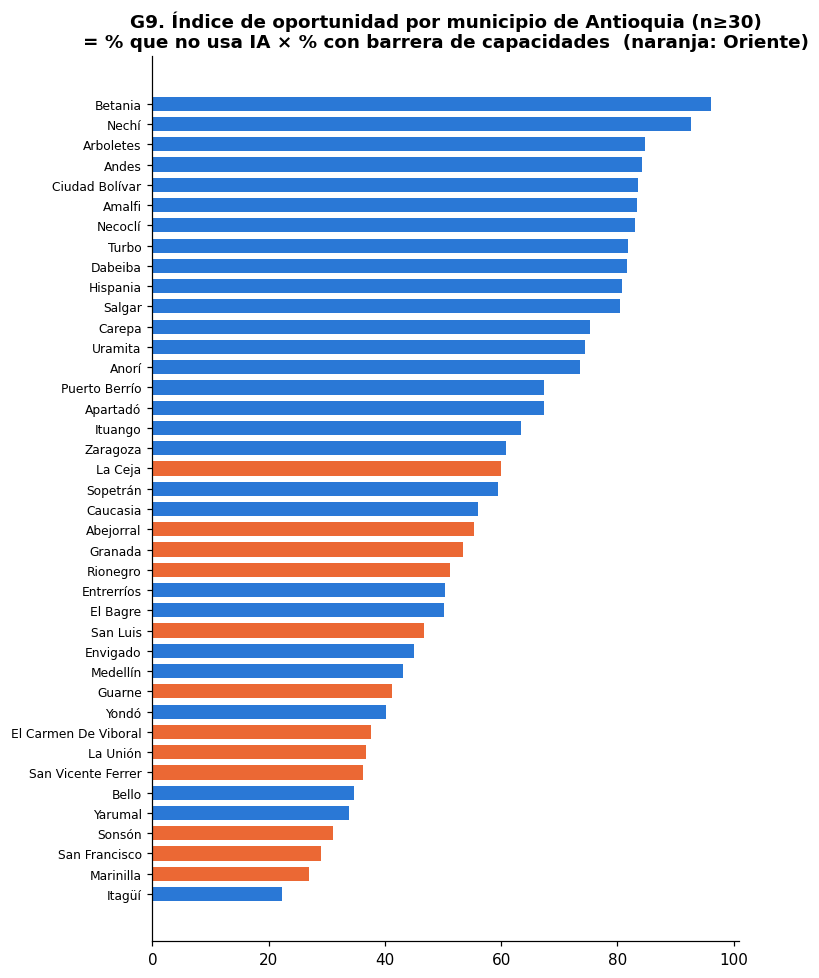

41 de los 125 municipios de Antioquia tienen personas en la muestra; 40 tienen 30 o más personas y aparecen en G9; 12 del Oriente.
                    personas_muestra  uso_ia_%  incidente_%  rural_%
Resto de Antioquia            4093.0      16.1         14.5     11.8
Oriente (zoom)                1126.0      16.6          3.5     35.4


In [14]:
# Este bloque resume el uso de IA por municipio de Antioquia, calcula el índice de oportunidad y dibuja el Gráfico G9.
# 1. La función agg calcula, para cada municipio: personas en la muestra (n), porcentaje ponderado que usa IA con su intervalo de confianza aproximado, porcentaje con barrera de capacidades, porcentaje con incidentes y porcentaje de población fuera de la cabecera.
# 2. Se conservan solo los municipios con 30 personas o más en la muestra, porque con menos los porcentajes son muy inestables.
# 3. El índice de oportunidad es el porcentaje que no usa IA multiplicado por el porcentaje con barrera de capacidades: es alto donde falta adopción y esa falta se debe a falta de conocimiento.
# 4. Se leen los nombres y las coordenadas de los municipios desde el archivo DIVIPOLA y se unen a la tabla.
# 5. Se marca la subregión Oriente para mostrarla como zoom.
# 6. Se dibuja el Gráfico G9 (naranja = Oriente) y se imprimen las cifras del Oriente frente al resto de Antioquia.
# 7. Se guardan las tablas zoom_oriente.csv y municipios_antioquia.csv.
def agg(x):
    w=x.fex; n=len(x); p=wm(x.ia,w); xb=x.dropna(subset=['barrera_capac'])
    return pd.Series({'n':n,'ia_pct':100*p,'ia_ic95':100*1.96*np.sqrt(max(p*(1-p),1e-9)/n),'barrera_pct':100*wm(xb.barrera_capac,xb.fex) if len(xb) else np.nan,'incidente_pct':100*wm(x.incidente,w),'rural_pct':100*wm((x.clase!=1)*1,w)})
M=a.groupby('mpio').apply(agg).reset_index(); M=M[M.n>=30].copy()
M['oportunidad_idx']=((100-M.ia_pct)/100*M.barrera_pct/100*100).round(1)
dv=pd.read_csv(RUTA_DIVIPOLA,encoding='utf-8'); dv.columns=['cod_dpto','dpto_nombre','cod_mpio','municipio','tipo','lon','lat']
for c in ['lon','lat']: dv[c]=pd.to_numeric(dv[c].astype(str).str.replace(',','.'),errors='coerce')
dv['mpio']=pd.to_numeric(dv.cod_mpio,errors='coerce')
M=M.merge(dv[['mpio','municipio','lon','lat']],on='mpio',how='left'); M['municipio']=M.municipio.str.title()
# Se define la subregión Oriente de Antioquia (23 municipios) con sus códigos DANE de municipio.
ORIENTE={5002,5021,5055,5148,5197,5206,5313,5318,5321,5376,5400,5440,5483,5541,5607,5615,5649,5652,5660,5667,5674,5697,5756}
M['oriente']=M.mpio.isin(ORIENTE)*1; a['oriente']=a.mpio.isin(ORIENTE)*1
M=M.sort_values('oportunidad_idx')
fig,ax=plt.subplots(figsize=(7,9)); ax.barh(M.municipio.astype(str),M.oportunidad_idx,color=[NARANJA if o else AZUL for o in M.oriente],height=.7); ax.tick_params(axis='y',labelsize=8)
ax.set_title('G9. Índice de oportunidad por municipio de Antioquia (n≥30)\n= % que no usa IA × % con barrera de capacidades  (naranja: Oriente)'); plt.tight_layout()
plt.savefig(SALIDA + 'graficos/g09_oportunidad_municipios.png',
            dpi=150, bbox_inches='tight', facecolor='white')   # guarda el gráfico en PNG
plt.show()
print(a.mpio.nunique(),'de los 125 municipios de Antioquia tienen personas en la muestra;',len(M),'tienen 30 o más personas y aparecen en G9;', int(M.oriente.sum()),'del Oriente.')
zo=a.groupby('oriente').apply(lambda x: pd.Series({'personas_muestra':len(x),'uso_ia_%':100*wm(x.ia,x.fex),'incidente_%':100*wm(x.incidente,x.fex),'rural_%':100*wm((x.clase!=1)*1,x.fex)})).round(1); zo.index=['Resto de Antioquia','Oriente (zoom)']; print(zo)
zo.reset_index().rename(columns={'index':'zona'}).to_csv(SALIDA+'zoom_oriente.csv',index=False)
M.round(2).to_csv(SALIDA+'municipios_antioquia.csv',index=False)

**G9 · Lectura y advertencia.** El índice combina *cuánto falta por adoptar* (no usa IA) con *cuánto se debe a falta de capacidades* (la parte donde una célula Senior sí aporta). Los municipios con más oportunidad (Betania, Nechí, Arboletes, Andes y Ciudad Bolívar, con 83 a 96 puntos) tienen muestras pequeñas (38 a 108 personas) y varios son rurales (la relación entre ruralidad e índice es moderada, 0,42); el más bajo es Itagüí (22,3). El **Oriente** va en naranja como zoom (12 de sus 23 municipios tienen muestra suficiente): su uso de IA es parecido al del resto de Antioquia (16,6 % frente a 16,1 %), pero es mucho más rural (35 % frente a 12 %) y reporta menos incidentes (3,5 % frente a 14,5 %).
**Advertencia:** ENTIC Hogares está diseñada para resultados nacionales y departamentales; los municipios aquí tienen entre 33 y unas pocas decenas o cientos de personas con respuesta, con intervalos de confianza amplios. Se usan para *priorizar dónde mirar primero*, no para publicar cifras municipales.
**Por qué faltan municipios en G9.** Solo 41 de los 125 municipios de Antioquia tienen personas encuestadas en ENTIC Hogares 2024, y G9 muestra los 40 que tienen 30 personas o más. Los demás, como Jardín, no aparecen porque la encuesta no llegó a ellos o llegó a muy pocas personas; no es un error del gráfico.

## Fase 5 · De la exploración al producto: el autodiagnóstico de 10 preguntas
El pre-proyecto plantea una web de autodiagnóstico gratuita que capta prospectos y los orienta hacia servicios de una célula Senior. Con datos de **personas** (no empresas) se puede hacer así de forma honesta:

| # | Pregunta al usuario | Variable ENTIC equivalente |
|---|---|---|
| 1 | ¿Qué edad tiene? | `iii7r1c1` |
| 2 | ¿Cuál es su nivel educativo? | `iii10r1c1` |
| 3 | ¿Vive en cabecera, centro poblado o rural? | `p3r1c1` |
| 4 | ¿Trabaja por cuenta propia, como profesional independiente o como empleador? (si no trabajó la semana pasada, se toma como no) | `iii15r1c1` |
| 5 | ¿Usa herramientas de IA? | `iv10r30c1` |
| 6 | ¿Compra o vende por internet? | `iv10r7c1` / `iv10r8c1` |
| 7 | ¿Usa fórmulas básicas en una hoja de cálculo sin pedir ayuda? | `iv4r6c1` |
| 8 | ¿Usa software de protección (antivirus, firewall, antispyware)? | `v1r1c1` |
| 9 | ¿Define contraseñas seguras (letras, números y caracteres especiales)? | `v1r2c1` |
| 10 | ¿Hace copias de seguridad (Back up) de su información? | `v1r3c1` |

Con esas 10 respuestas la herramienta entrega (a) un **índice de exposición a incidentes digitales** según el perfil de uso (edad, educación, zona, ocupación, IA, compras/ventas, hoja de cálculo); (b) una **regla de gobernanza** con las tres prácticas de protección (preguntas 8–10), que *no* entran al modelo estadístico porque, como mostró la pregunta 2, en los datos las protecciones aparecen más entre quienes ya sufrieron incidentes; y (c), si la persona no usa IA, la probabilidad de que su barrera sea de capacidades. Se entrena con **adultos con internet de todo el país** (más datos) y se verifica el desempeño en Antioquia.

In [15]:
# Este bloque prepara los datos y entrena los dos modelos del autodiagnóstico de 10 preguntas.
# 1. Se toman los adultos con internet de todo el país (ad), porque con más datos los modelos son más estables; después se verifica el resultado solo en Antioquia.
# 2. Se construyen las variables que corresponden a las 10 preguntas: nivel educativo en 5 grupos (educ5), compra o vende por internet, fórmulas en hoja de cálculo, antivirus, contraseñas seguras y copias de seguridad (todas con 1 = Sí y 0 = No), y si es independiente o patrón (los vacíos cuentan como 0).
# 3. Se entrena el modelo de exposición a incidentes con siete variables de perfil y uso (FEXP); las tres protecciones no entran porque en los datos aparecen más entre quienes ya sufrieron incidentes.
# 4. Se entrena el modelo de barrera de capacidades solo con quienes no usan IA y usando las nueve variables de las preguntas que no incluyen el uso de IA (F9).
# 5. En ambos casos se separa 80/20 por hogar y se imprime el Índice C de la prueba.
# 6. No se usa class_weight para que las probabilidades salgan calibradas: el resultado se lee como probabilidad y no solo como clasificación.
ad=b[b.edad>=18].copy()
ad['educ5']=ad.educ.map(lambda e: np.nan if pd.isna(e) else 1 if e<=3 else 2 if e<=5 else 3 if e<=9 else 4 if e<=11 else 5)
ad['compra_vende']=((ad.iv10r7c1==1)|(ad.iv10r8c1==1)).astype(float).where(ad.iv10r7c1.notna())
ad['hoja_calculo']=(ad.iv4r6c1==1)*1.0; ad['antivirus']=(ad.v1r1c1==1)*1.0; ad['claves']=(ad.v1r2c1==1)*1.0; ad['respaldo']=(ad.v1r3c1==1)*1.0
ad['indep']=ad.indep_patron.fillna(0)
F10=['edad','educ5','clase','indep','ia','compra_vende','hoja_calculo','antivirus','claves','respaldo']
FEXP=['edad','educ5','clase','indep','ia','compra_vende','hoja_calculo']
t1=ad.dropna(subset=FEXP+['incidente']); print('Adultos para el modelo de incidentes:', len(t1), '| prevalencia %.3f' % t1.incidente.mean())
tr,te=next(GroupShuffleSplit(1,test_size=.2,random_state=7).split(t1,groups=t1.UID_ENCUESTA)); T,V=t1.iloc[tr],t1.iloc[te]
LRC=lambda:make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000))   # sin class_weight: probabilidades calibradas
m_inc=LRC().fit(T[FEXP],T.incidente); p=m_inc.predict_proba(V[FEXP])[:,1]
print('Índice de exposición (7 variables de perfil y uso) — Índice C test nacional: %.3f' % roc_auc_score(V.incidente,p))
Va=V[V.dpto==5]; print('   …solo Antioquia en test: Índice C %.3f (n=%d)' % (roc_auc_score(Va.incidente,m_inc.predict_proba(Va[FEXP])[:,1]),len(Va)))
F9=[f for f in F10 if f!='ia']; t2=ad[(ad.ia==0)].dropna(subset=F9+['barrera_capac'])
tr2,te2=next(GroupShuffleSplit(1,test_size=.2,random_state=7).split(t2,groups=t2.UID_ENCUESTA)); T2,V2=t2.iloc[tr2],t2.iloc[te2]
m_bar=LRC().fit(T2[F9],T2.barrera_capac); print('Modelo de barrera de capacidades (9 preguntas, no usuarios de IA) — Índice C test: %.3f (n train %d)' % (roc_auc_score(V2.barrera_capac,m_bar.predict_proba(V2[F9])[:,1]),len(T2)))

Adultos para el modelo de incidentes: 78259 | prevalencia 0.083
Índice de exposición (7 variables de perfil y uso) — Índice C test nacional: 0.701
   …solo Antioquia en test: Índice C 0.779 (n=1075)
Modelo de barrera de capacidades (9 preguntas, no usuarios de IA) — Índice C test: 0.798 (n train 53648)


**Función de diagnóstico (qué y por qué).** Con las 10 respuestas se aplican la regla de gobernanza y los dos modelos, y se devuelve el segmento y el índice de exposición. Los tres casos son ficticios.

In [16]:
# Este bloque define la función diagnosticar y la prueba con tres personas ficticias.
# 1. La función recibe las 10 respuestas del autodiagnóstico.
# 2. Con las 7 variables de perfil y uso calcula la exposición a incidentes digitales (probabilidad que da el modelo).
# 3. Suma las tres protecciones básicas (antivirus, contraseñas seguras y copias de seguridad).
# 4. Si la persona usa IA y tiene una protección o ninguna, el segmento es «poca protección básica»; si usa IA y tiene más protecciones, es «usuario protegido».
# 5. Si no usa IA, calcula la probabilidad de que su barrera sea de capacidades y propone acompañamiento de iniciación (50 % o más) o sensibilización (menos de 50 %).
# 6. Al final se aplican tres casos ficticios y se imprime el resultado de cada uno.
# Nota: esta regla usa solo 3 prácticas de protección y por eso se llama «poca protección básica» y no coincide con el riesgo crítico del tablero, que usa las 11 prácticas.
def diagnosticar(edad,educ5,clase,indep,usa_ia,compra_vende,hoja_calculo,antivirus,claves,respaldo):
    r=dict(edad=edad,educ5=educ5,clase=clase,indep=indep,ia=usa_ia,compra_vende=compra_vende,hoja_calculo=hoja_calculo,antivirus=antivirus,claves=claves,respaldo=respaldo)
    x=pd.DataFrame([r])[FEXP]; p_inc=float(m_inc.predict_proba(x)[0,1]); prot=antivirus+claves+respaldo
    if usa_ia and prot<=1:   seg='POCA PROTECCIÓN BÁSICA: usa IA con pocas protecciones → gobernanza de datos y ciberseguridad'
    elif usa_ia:             seg='USUARIO PROTEGIDO: listo para agentes de flujo de procesos y buenas prácticas de IA'
    else:
        p_bar=float(m_bar.predict_proba(pd.DataFrame([r])[F9])[0,1])
        seg=f'NO USA IA: {p_bar:.0%} de probabilidad de barrera de capacidades → ' + ('acompañamiento Senior de iniciación' if p_bar>=.5 else 'sensibilización (probablemente no la ve necesaria)')
    return seg, round(p_inc,3)
ej={'Doña Luz, 62, primaria, rural, cuenta propia, no usa IA':(62,1,3,1,0,0,0,0,0,0),
    'Carlos, 58, universitario, cabecera, patrón, usa IA, sin protecciones':(58,4,1,1,1,1,1,0,0,0),
    'Marta, 41, posgrado, cabecera, usa IA, protegida':(41,5,1,0,1,1,1,1,1,1)}
for k,v in ej.items(): sg,pe=diagnosticar(*v); print(k,'\n   →',sg,'| exposición a incidentes según su perfil de uso: %.0f%%\n' % (100*pe))

Doña Luz, 62, primaria, rural, cuenta propia, no usa IA 
   → NO USA IA: 93% de probabilidad de barrera de capacidades → acompañamiento Senior de iniciación | exposición a incidentes según su perfil de uso: 4%

Carlos, 58, universitario, cabecera, patrón, usa IA, sin protecciones 
   → POCA PROTECCIÓN BÁSICA: usa IA con pocas protecciones → gobernanza de datos y ciberseguridad | exposición a incidentes según su perfil de uso: 29%

Marta, 41, posgrado, cabecera, usa IA, protegida 
   → USUARIO PROTEGIDO: listo para agentes de flujo de procesos y buenas prácticas de IA | exposición a incidentes según su perfil de uso: 28%



**Qué es y qué no es esta herramienta.** Es un *insumo orientativo* de priorización: no es una evaluación individual ni de una empresa, y no sustituye una auditoría. Los ejemplos de arriba son personas ficticias para ilustrar el flujo. Para pasar a microempresarios y pymes habría que reentrenar con datos de empresas (hoy no existen en abierto para 2024 en adelante); la estructura de las 10 preguntas, el embudo y la captación de prospectos se mantienen y los *pesos* del modelo se reemplazan.

**Exportación (qué y por qué).** Se guardan los datos limpios y las tablas que alimentan el tablero de Power BI (departamentos, segmentos, municipios, benchmark y contexto de ColCERT).

In [17]:
# Este bloque guarda los datos limpios y las tablas que alimentan el tablero de Power BI en la carpeta de salidas.
# 1. Se crea la columna segmento, que clasifica a cada persona en uno de cuatro grupos: usa IA con baja protección, usa IA protegido, no usa IA con barrera de capacidades y no usa IA por otra razón.
# 2. Se guarda la tabla principal (dataset_modelo_antioquia.csv) con una fila por persona de Antioquia.
# 3. Se guardan el uso de IA por departamento, el reparto de segmentos y las métricas de los modelos (metricas_modelos_q1.csv y cv_q1.csv).
# 4. Se guarda el benchmark por zona (benchmark_clase.csv) y el contexto nacional de ColCERT (contexto_colcert.csv).
# 5. Se imprime la lista de archivos guardados para confirmar que quedaron todos.
a['segmento']=np.select([(a.ia==1)&(a.seg11<=thr),(a.ia==1),(a.ia==0)&(a.barrera_capac==1),(a.ia==0)&(a.barrera_capac==0)],['Usa IA con baja protección','Usa IA protegido','No usa IA: barrera de capacidades','No usa IA: otra razón'],default='No usa IA: sin dato de razón')
a.to_csv(SALIDA+'dataset_modelo_antioquia.csv',index=False)
dep[['dpto','nombre','n','ia']].rename(columns={'ia':'uso_ia_pct'}).to_csv(SALIDA+'uso_ia_departamento.csv',index=False)
sg=a.groupby('segmento').apply(lambda x: pd.Series({'personas_muestra':len(x),'pct_ponderado':100*x.fex.sum()/a.fex.sum()})).round(1).reset_index(); sg.to_csv(SALIDA+'segmentos_antioquia.csv',index=False); print(sg)
mt.to_csv(SALIDA+'metricas_modelos_q1.csv',index=False); cv.to_csv(SALIDA+'cv_q1.csv',index=False)
# Benchmark de percentiles para el tablero (Antioquia)
bm=a.groupby('clase_g').apply(lambda x: pd.Series({'n':len(x),'ia_pct':100*wm(x.ia,x.fex),'seg11_media':x.seg11.mean(),'skills_media':x.skills_n.mean(),'incidente_pct':100*wm(x.incidente,x.fex)})).round(2).reset_index(); bm.to_csv(SALIDA+'benchmark_clase.csv',index=False)
pd.DataFrame({'anio':[2024,2025],'incidentes_gestionados_colcert':[1427,697],'fuente':['MinTIC / ColCERT (comunicado de prensa, actualizado el 2 de abril de 2026)']*2}).to_csv(SALIDA+'contexto_colcert.csv',index=False)
print(os.listdir(SALIDA))

                            segmento  personas_muestra  pct_ponderado
0  No usa IA: barrera de capacidades            2858.0           45.8
1              No usa IA: otra razón            1741.0           38.0
2         Usa IA con baja protección             223.0            4.7
3                   Usa IA protegido             397.0           11.5
['graficos', 'zoom_oriente.csv', 'municipios_antioquia.csv', 'metricas_riesgo_critico.csv', 'uso_ia_departamento.csv', 'contexto_colcert.csv', 'cv_q1.csv', 'metricas_modelos_q1.csv', 'benchmark_clase.csv', 'dataset_modelo_antioquia.csv', 'segmentos_antioquia.csv', 'Proyecto_Final_Horizonte_Senior_Antioquia26_ejecutado.ipynb', 'qr_autodiagnostico.png']


**Copia del cuaderno ejecutado (qué y por qué).** Se pide a Colab el contenido actual del cuaderno, con todos sus resultados, y se guarda como archivo .ipynb en la carpeta de salidas.
Así el cuaderno ejecutado queda junto a los CSV y los gráficos.


In [ ]:
# Este bloque guarda una copia del cuaderno ejecutado en la carpeta de salidas.
# 1. Se pide a Colab el contenido actual del cuaderno (código, textos y resultados).
# 2. Se escribe como archivo .ipynb dentro de SALIDA.
# 3. Si no se está en Colab, o si la copia falla, se imprime un aviso y el cuaderno sigue funcionando.
import json
try:
    from google.colab import _message
    cuaderno = _message.blocking_request('get_ipynb', request='', timeout_sec=120)['ipynb']
    with open(SALIDA + 'Proyecto_Final_Horizonte_Senior_Antioquia26_ejecutado.ipynb', 'w', encoding='utf-8') as f:
        json.dump(cuaderno, f, ensure_ascii=False, indent=1)
    print('Copia del cuaderno guardada en', SALIDA)
except Exception as e:
    print('No se pudo guardar la copia del cuaderno:', e)

**Cierre del guardado (qué y por qué).** En Colab, los archivos escritos en el Drive se sincronizan en segundo plano; esta celda fuerza que todo quede guardado antes de cerrar la sesión.


In [ ]:
# Este bloque cierra la conexión con el Drive y fuerza que todos los archivos queden guardados.
# 1. drive.flush_and_unmount() espera a que Colab termine de sincronizar los CSV, los gráficos y la copia del cuaderno.
# 2. Fuera de Colab no hace nada.
try:
    from google.colab import drive
    drive.flush_and_unmount()          # asegura que CSV y gráficos quedaron guardados en el Drive
except ImportError:
    pass


## Originalidad e insight: lo que este análisis aporta
Cinco hallazgos que no se ven a simple vista y que cambian qué haría una célula Senior:
1. **El acompañamiento debe ser individual, no solo territorial.** La madurez digital propia sube el Índice C de 0,84 a 0,91; la brecha frente al promedio del municipio no agrega nada (0,910). Importa quién es la persona, no solo dónde vive.
2. **Usar IA expone: 2,4 veces más incidentes** (25,4 % frente a 10,6 %), y aun así 3 de cada 10 usuarios de IA (29 %) tienen pocas protecciones. Pero el índice de protección *no* predice incidentes (quienes protegen más reportan más): por eso el riesgo crítico se presenta como regla de exposición y no como predicción de incidentes. Lo que sí se puede anticipar, de forma moderada, es quién cae en esa regla a partir de su perfil, sus habilidades y sus usos (Índice C 0,78 en validación cruzada). Reportar este resultado negativo es parte del aporte.
3. **Necesidad no es demanda.** El 55 % de quienes no usan IA dice que no sabe qué es o cómo usarla, pero entre ellos el interés en capacitarse en programas de entidades públicas es menor (63 % frente a 75 %, en un grupo de 621 personas): hay que ir a buscarlos, con confianza.
4. **La brecha de edad es el hallazgo central para Horizonte Senior:** solo el 7,3 % de las personas de 45 a 64 años usa IA, frente al 22,3 % de las de 18 a 44; y entre los senior con estudios universitarios (55–64 años) el uso es de 23 %: hay capacidad instalada sin aprovechar, justo el público de este programa.
5. **El enfoque:** ante la falta de datos abiertos de empresas 2024+, el proyecto parte de personas adultas y deja el camino listo (10 preguntas, embudo, reentrenamiento) para microempresas y pymes. Quienes hacemos el análisis somos parte de la población que el modelo busca acompañar.

## Fase 6 · Limitaciones y siguientes pasos (con honestidad)
1. **Persona, no empresa.** ENTIC Hogares mide personas y hogares. Para empresas no hay microdatos abiertos 2024+ con madurez digital; el pre-proyecto de autodiagnóstico para pymes queda como *segunda fase* con datos que la propia célula recoja con consentimiento.
2. **Asociación, no causalidad** (pregunta 1) y **regla no validada contra incidentes** (pregunta 2): se declaran como hipótesis de trabajo. El modelo de riesgo crítico (pregunta 3) predice una etiqueta que definimos con una regla, con una muestra pequeña (usuarios de IA de Antioquia), por lo que sirve para priorizar y no como diagnóstico individual.
3. **Municipios con muestra pequeña.** Solo 41 de los 125 municipios de Antioquia tienen datos y 40 alcanzan 30 personas. Sirven para priorizar, no para publicar cifras locales.
4. **Intervalos de confianza aproximados.** Los porcentajes se ponderan con el factor de expansión `FEX_c`. Los intervalos reportados (`ia_ic95`) suponen muestreo aleatorio simple y no consideran el diseño muestral de ENTIC (conglomerados por hogar y pesos muy desiguales), por lo que **subestiman la incertidumbre real**. Sirven para comparar la precisión relativa entre municipios, no como intervalos exactos. Una estimación rigurosa requeriría las variables de diseño (estrato y conglomerado) y errores estándar por linealización o remuestreo.
5. **Población analizada.** Son adultos (18 años o más) que usan internet: los resultados no describen a quienes no usan internet ni a los menores (quienes no usan internet, que responden la pregunta IV.19, quedan fuera).
6. **Medición.** Todo es autorreporte. Las 13 tareas digitales se preguntan «en el computador de escritorio, portátil o tableta», por lo que quien solo usa celular puede quedar subestimado. La pregunta de interés en capacitación (IV.14C) solo se hace a un grupo seleccionado (621 adultos), de modo que no representa a todos los adultos.
7. **Definición de la barrera de capacidades.** Solo cuenta «No sabe qué es la IA» y «No sabe utilizar herramientas de IA». No incluye el costo, la falta de herramientas o datos ni las restricciones del empleador, que son barreras de acceso y no de conocimiento.
8. **Etiquetas.** El cuestionario nombra el ítem `p3r1c1` como «Clase». El diccionario en línea no trae etiquetas de valores, pero la metodología del DANE define 1 = cabecera, 2 = centros poblados y 3 = rural disperso.
9. **Privacidad.** La web de autodiagnóstico debe cumplir la Ley 1581 de 2012: consentimiento informado, finalidad clara y mínimos datos. No debe afirmar que «todo corre en el dispositivo» si se captura correo o NIT.
10. **Siguiente paso:** una célula Senior aplica las 10 preguntas a personas y microempresarios reales (con consentimiento) para validar y reentrenar el modelo.

## Contexto externo · ILIA 2026 (CEPAL/CENIA)
El Índice Latinoamericano de Inteligencia Artificial 2026 compara 20 países. **No se usa para entrenar ni validar modelos**: son 20 filas por país, sin datos de Antioquia ni de personas. Se usa solo como contexto y para justificar el paso de personas a empresas.

- **Colombia en la región:** 56,8 puntos, primer país «adoptante» (Chile, Brasil y Uruguay son «pioneros»). Gobernanza 80,9 puntos; factores habilitantes 46,4 (p. 20).
- **IA generativa:** el ILIA estima que el 20,4 % de la población colombiana de 15 a 64 años la usa (promedio regional 16,1 %; p. 160-161). Va en la misma dirección que el 17,8 % nacional y el 16,2 % de Antioquia (adultos) de ENTIC, pero la fuente (telemetría de Microsoft) y la población son distintas: es coherencia, no validación.
- **Adopción empresarial en Colombia (estimada):** 39,0 % en grandes, 18,0 % en medianas y 9,5 % en pequeñas (p. 147-148). Son estimaciones de un modelo econométrico (Katz y Jung, 2026), no una encuesta a empresas. Por eso este proyecto parte de personas y deja la etapa de microempresas y pymes como siguiente paso.
- **Ciberseguridad:** Colombia 66,6 puntos (puesto 12 de 20); en medidas organizacionales, 55,9 (puesto 18 de 20) (p. 200-203).

**Cita:** Soto, A., Durán, R., Moreno, A., Peralta, S., Rovira, S., Jordán, V. y Poveda, L. (Coords.) (2026). *Índice Latinoamericano de Inteligencia Artificial (ILIA) 2026*. CEPAL, LC/TS.2026/97. Presentado el 20 de octubre de 2026; la tabla resumida está en `contexto_ilia.csv`.